<a href="https://colab.research.google.com/github/Tushar-AI-Dev/Problem-solving-/blob/main/Daily_problems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

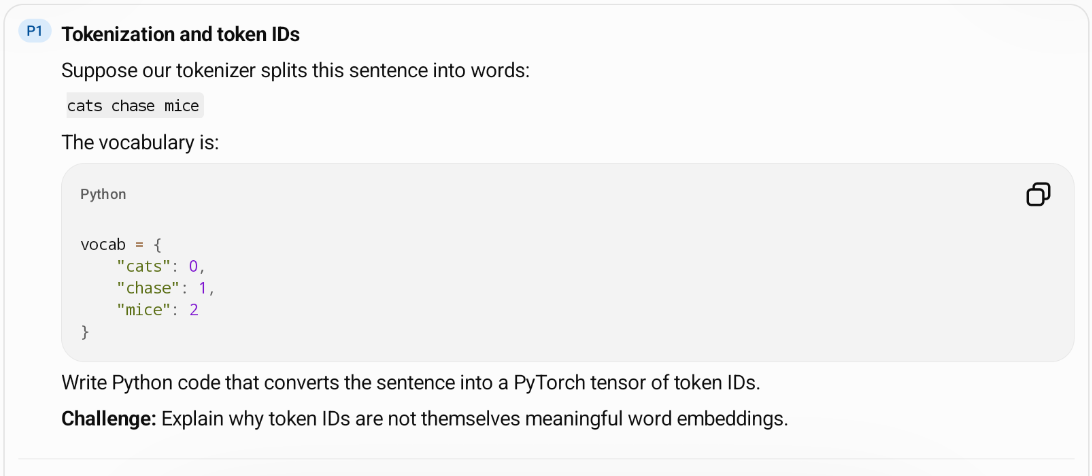

In [ ]:
seq =input('Enter a prompt here:     ')
vocab={}
i=0
x=seq.split(" ")
for c in x:
  vocab[c]=i
  i+=1
print(vocab)

token_ids=[vocab[word] for word in x]
print(token_ids
      )

#token ids are just number assigned to words/token they not contain any information they just point at what number partcular word in vocab exist while word
#embeddings store information related to word which learnt during training

Enter a prompt here:     I love machine learning
{'I': 0, 'love': 1, 'machine': 2, 'learning': 3}
[0, 1, 2, 3]


In [ ]:
#ADDITIONAL PROBLEM TO ABOVE WHAT IF ABOVE ONE TOKEN ENCOUNTER AGIN HOW YOU WILL SOLVE THE PROBLEM TO DONT GET ASSIGN ANOTHER TOKEN ID TO SAME TOKEN
seq =input('Enter a prompt here:     ')
vocab={}
i=0
x=seq.split(" ")
x=set(x)
for c in x:
  vocab[c]=i
  i+=1
print(vocab)

token_ids=[vocab[word] for word in x]
print(token_ids
      )

Enter a prompt here:     I love I love machine learning
{'learning': 0, 'I': 1, 'love': 2, 'machine': 3}
[0, 1, 2, 3]


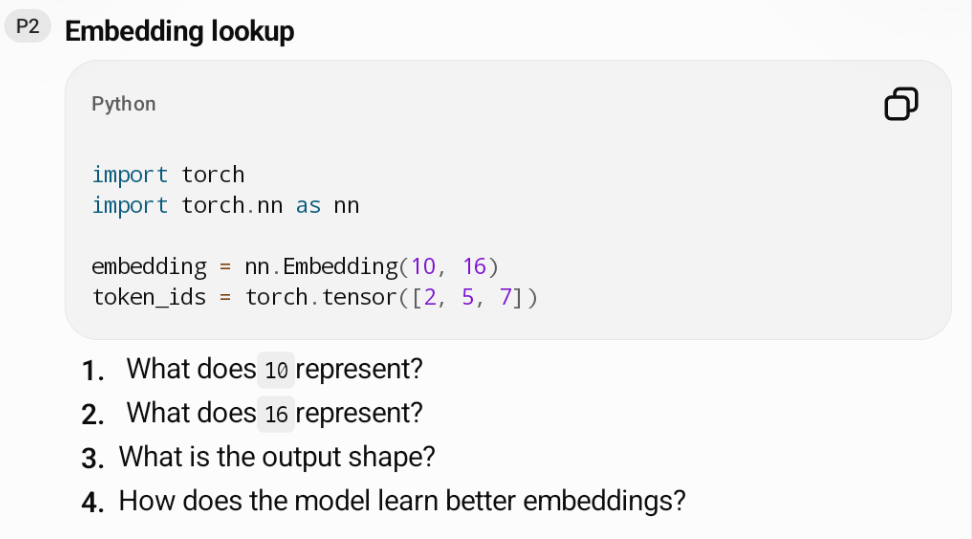

1.number of embeddings

2.embedding dimension

3.shape=(3,16)

4.initially there is random value generated by pytorch during traimning model learn and adjust this embedding values

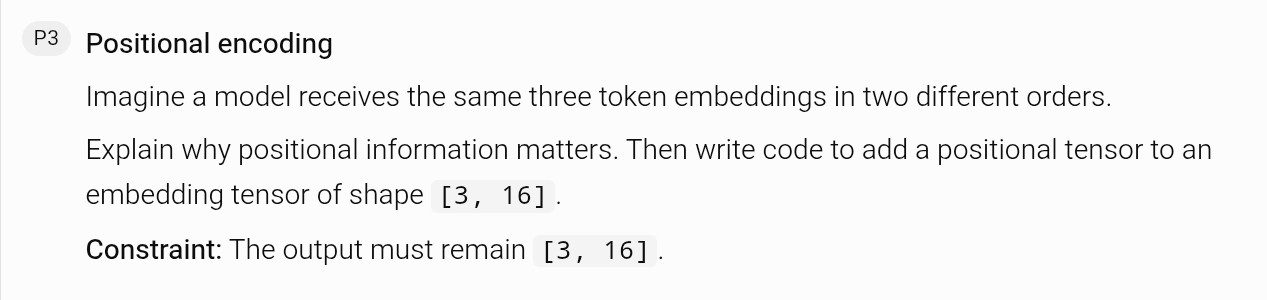

postional information matters because if same token appear on different position there is different meaning of each postion of token in seq.To preserve this information we use positional encoding

In [ ]:
import torch
t_embdd=torch.rand(3,16)
p_embdd=torch.rand(3,16)
input_representation=t_embdd+p_embdd
print(input_representation.shape)

torch.Size([3, 16])


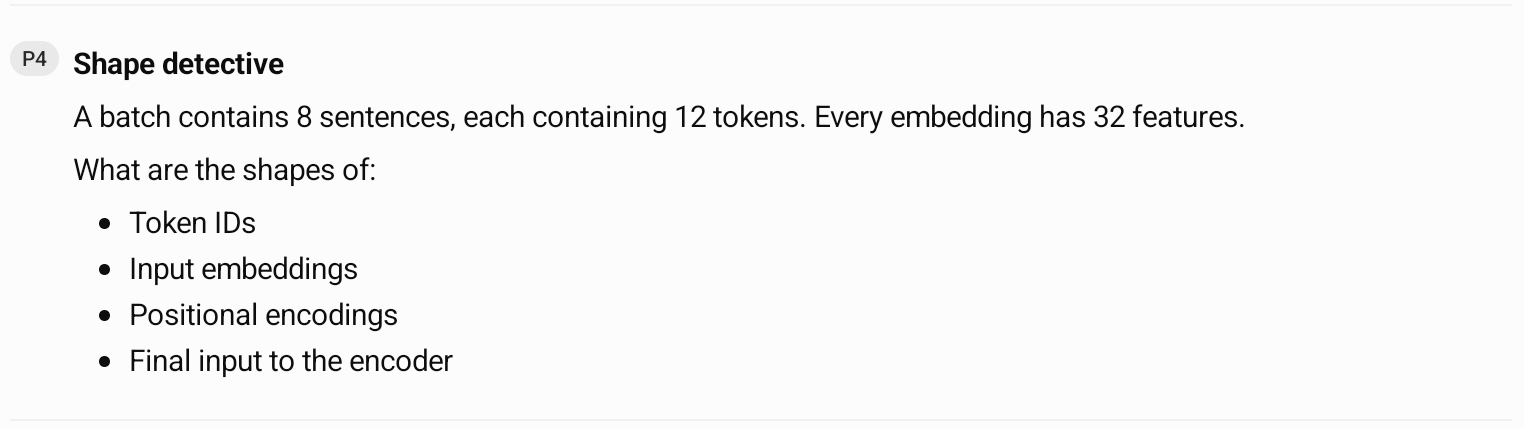

1.(8,12)
2.(8,12,32)
3.(12,32)
4.(8,12,32)

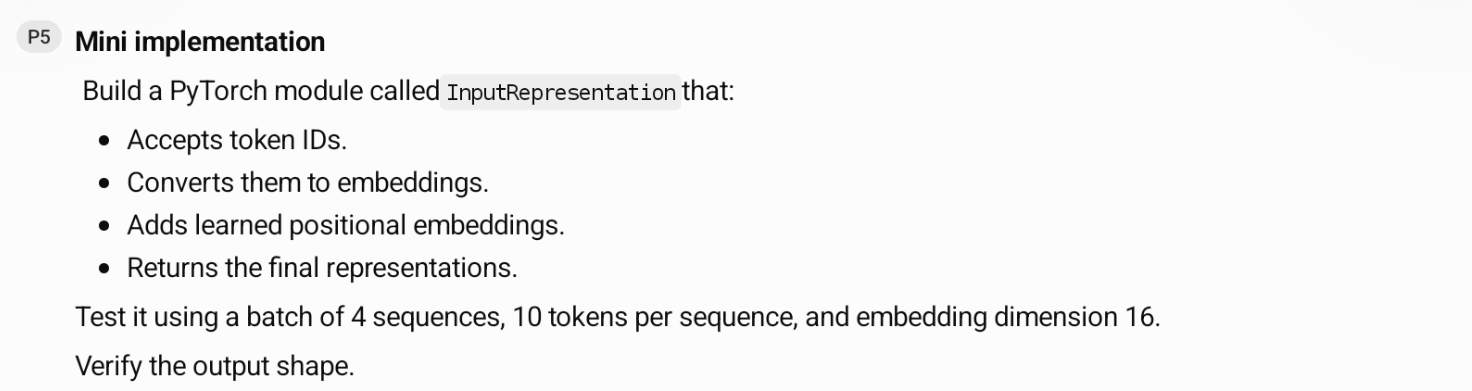

In [ ]:
from transformers import AutoTokenizer
tokenizer=AutoTokenizer.from_pretrained('bert-base-cased')
text1='The golden sun sets slowly over the calm blue ocean'#sequnce 1
token1=tokenizer.tokenize(text1)
token_id1=tokenizer.convert_tokens_to_ids(token1)
print(token_id1)


[1109, 5404, 3336, 3741, 2494, 1166, 1103, 5017, 2221, 5969]


In [ ]:
from transformers import AutoTokenizer
tokenizer=AutoTokenizer.from_pretrained('bert-base-cased')
text2='Reading books helps to expand your knowledge and mind everyday'#sequnce 2
token2=tokenizer.tokenize(text2)
token_id2=tokenizer.convert_tokens_to_ids(token2)
print(token_id2)

[8003, 2146, 6618, 1106, 7380, 1240, 3044, 1105, 1713, 11236]


In [ ]:
from transformers import AutoTokenizer
tokenizer=AutoTokenizer.from_pretrained('bert-base-cased')
text3='Cooking fresh food at home is always  healthy choice'#sequnce 3
token3=tokenizer.tokenize(text3)
token_id3=tokenizer.convert_tokens_to_ids(token3)
print(token_id3)

[6816, 1158, 4489, 2094, 1120, 1313, 1110, 1579, 8071, 3026]


In [ ]:
from transformers import AutoTokenizer
tokenizer=AutoTokenizer.from_pretrained('bert-base-cased')
text4='Learning new languages opens many doors for your future career'#sequnce 4
token4=tokenizer.tokenize(text4)
token_id4=tokenizer.convert_tokens_to_ids(token4)
print(token_id4)

[9681, 1207, 3483, 7086, 1242, 3581, 1111, 1240, 2174, 1578]


In [ ]:
import torch
import torch.nn as nn


class InputRepresentation(nn.Module):

    def __init__(self, vocab_size, embedding_dim, max_length):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        self.position_embedding = nn.Embedding(max_length, embedding_dim)

    def forward(self, token_ids):

        batch_size, seq_length = token_ids.shape
        embeddings = self.embedding(token_ids)
        positions = torch.arange(seq_length, device=token_ids.device)
        pos_embeddings = self.position_embedding(positions)
        output = embeddings + pos_embeddings

        return output


In [ ]:
token_ids = [token_id1, token_id2, token_id3, token_id4]
token_ids = torch.tensor(token_ids)

model = InputRepresentation(
    vocab_size=len(tokenizer),
    embedding_dim=16,
    max_length=32
)

output = model(token_ids)

print( token_ids.shape)
print( output.shape)

torch.Size([4, 10])
torch.Size([4, 10, 16])


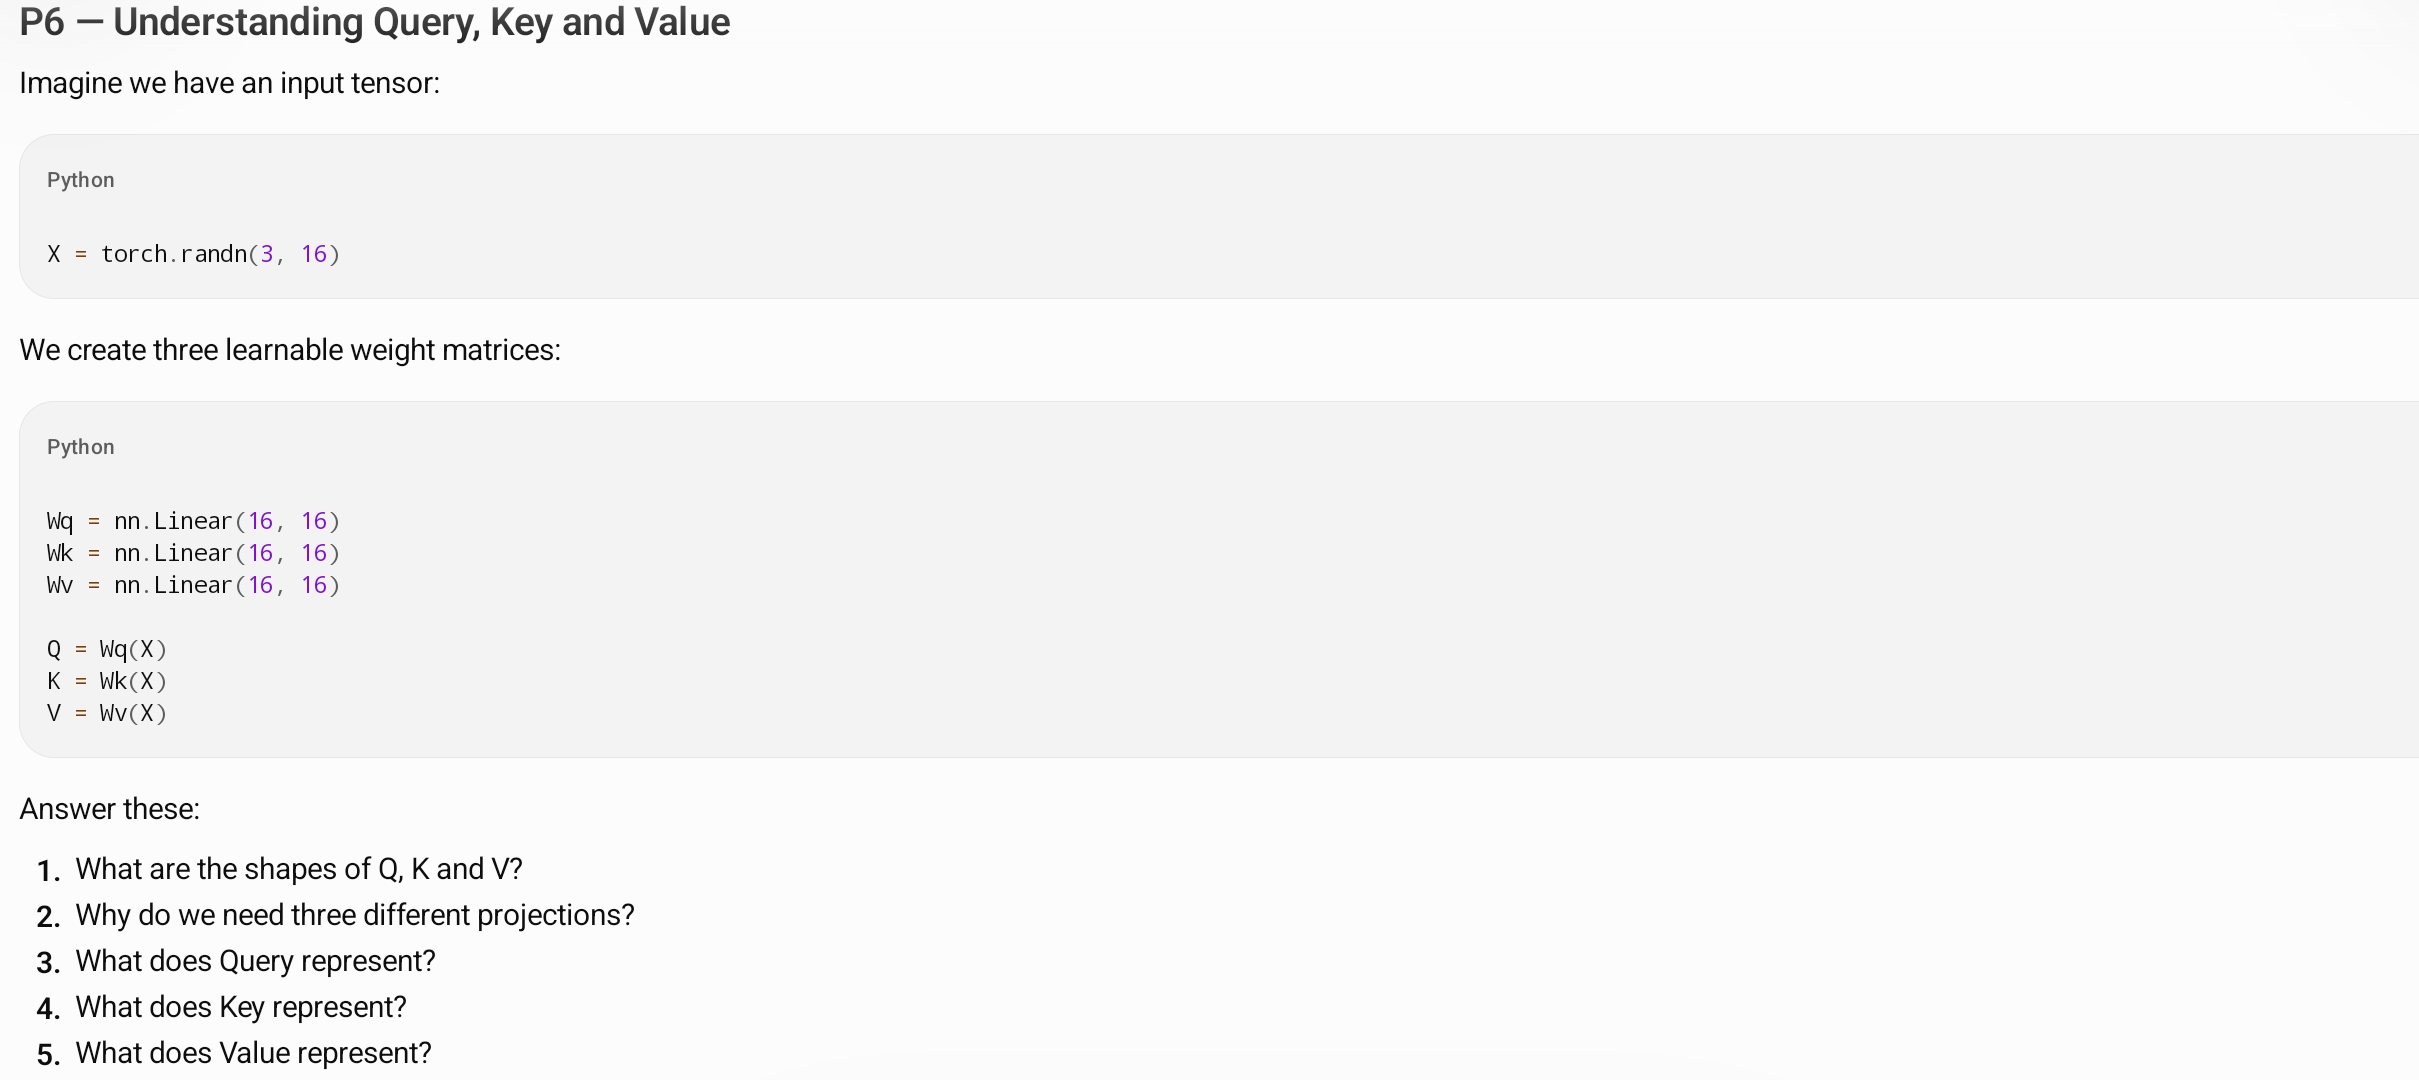

1.(3,16)@(16,16)--->(3,16)

2.We need Query ,keys,value because it is easy to gather information from token rather than evrytime cheking full information what a token contain even if it is relevant or not this time consuming somewhere disturbing ai system latency hence we query key most is needed instead up looking whole information of each token it looks only relevant token if it is useful then model can proceed furtehr without delaying.

3.query contains values for what it looking for ,what a current token required

4.keys contain label for what a is exactly a token store

5.value represent exact information a token store in it.

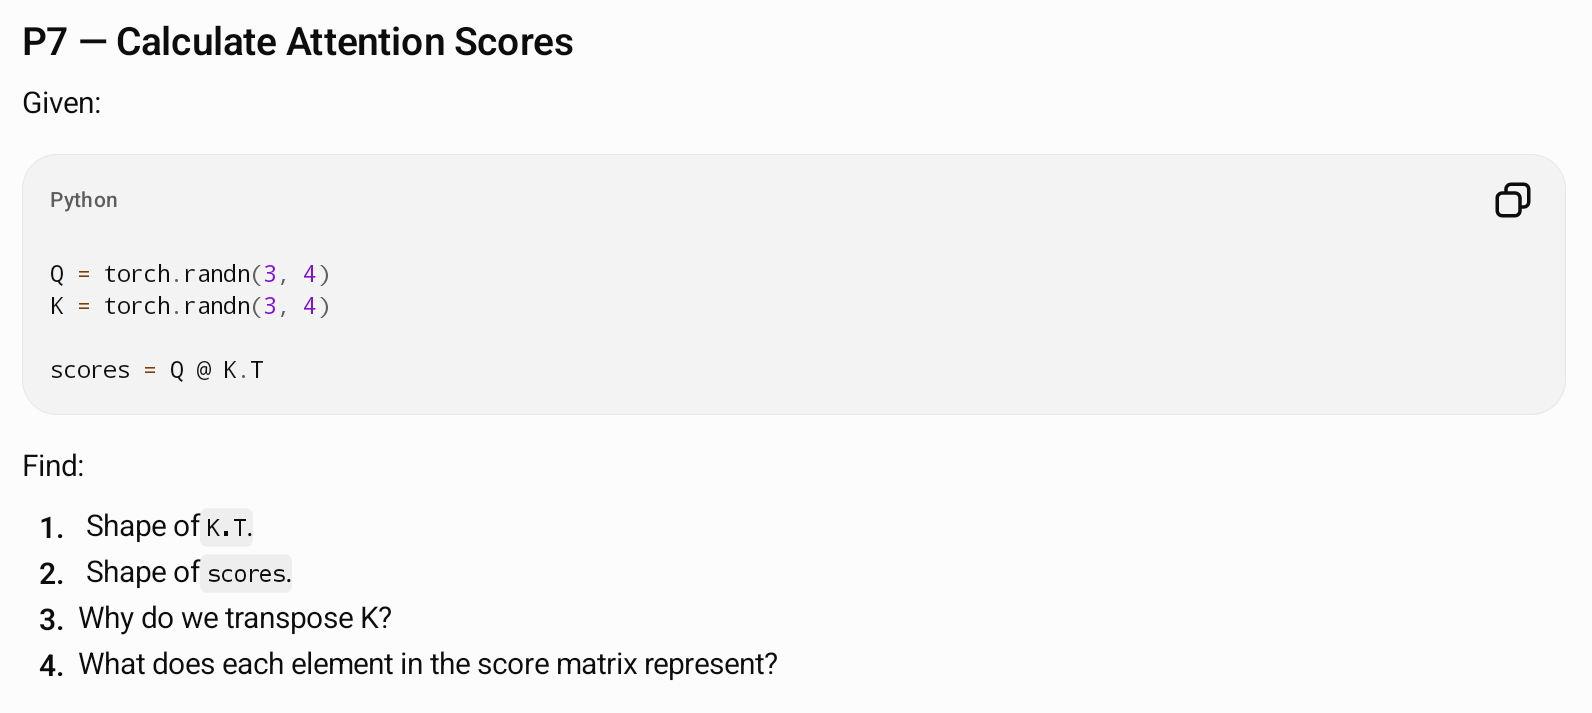

In [ ]:
import torch
Q=torch.randn(3,8) #query random matrix
K=torch.randn(3,8)
score=Q@K.T
print(f'shape of K.T  {K.T.shape}')
print(f'shape of score {score.shape}')
#To compare every Q against K we need to transpose it
#     K1     K2    K3
# Q1 0.545  0.483 0.269
# Q2 0.254  0.778 0.648
# Q3 0.215  0.456 0.468
#Each element in score matrix represent how much each query is relavant to each key

shape of K.T  torch.Size([8, 3])
shape of score torch.Size([3, 3])


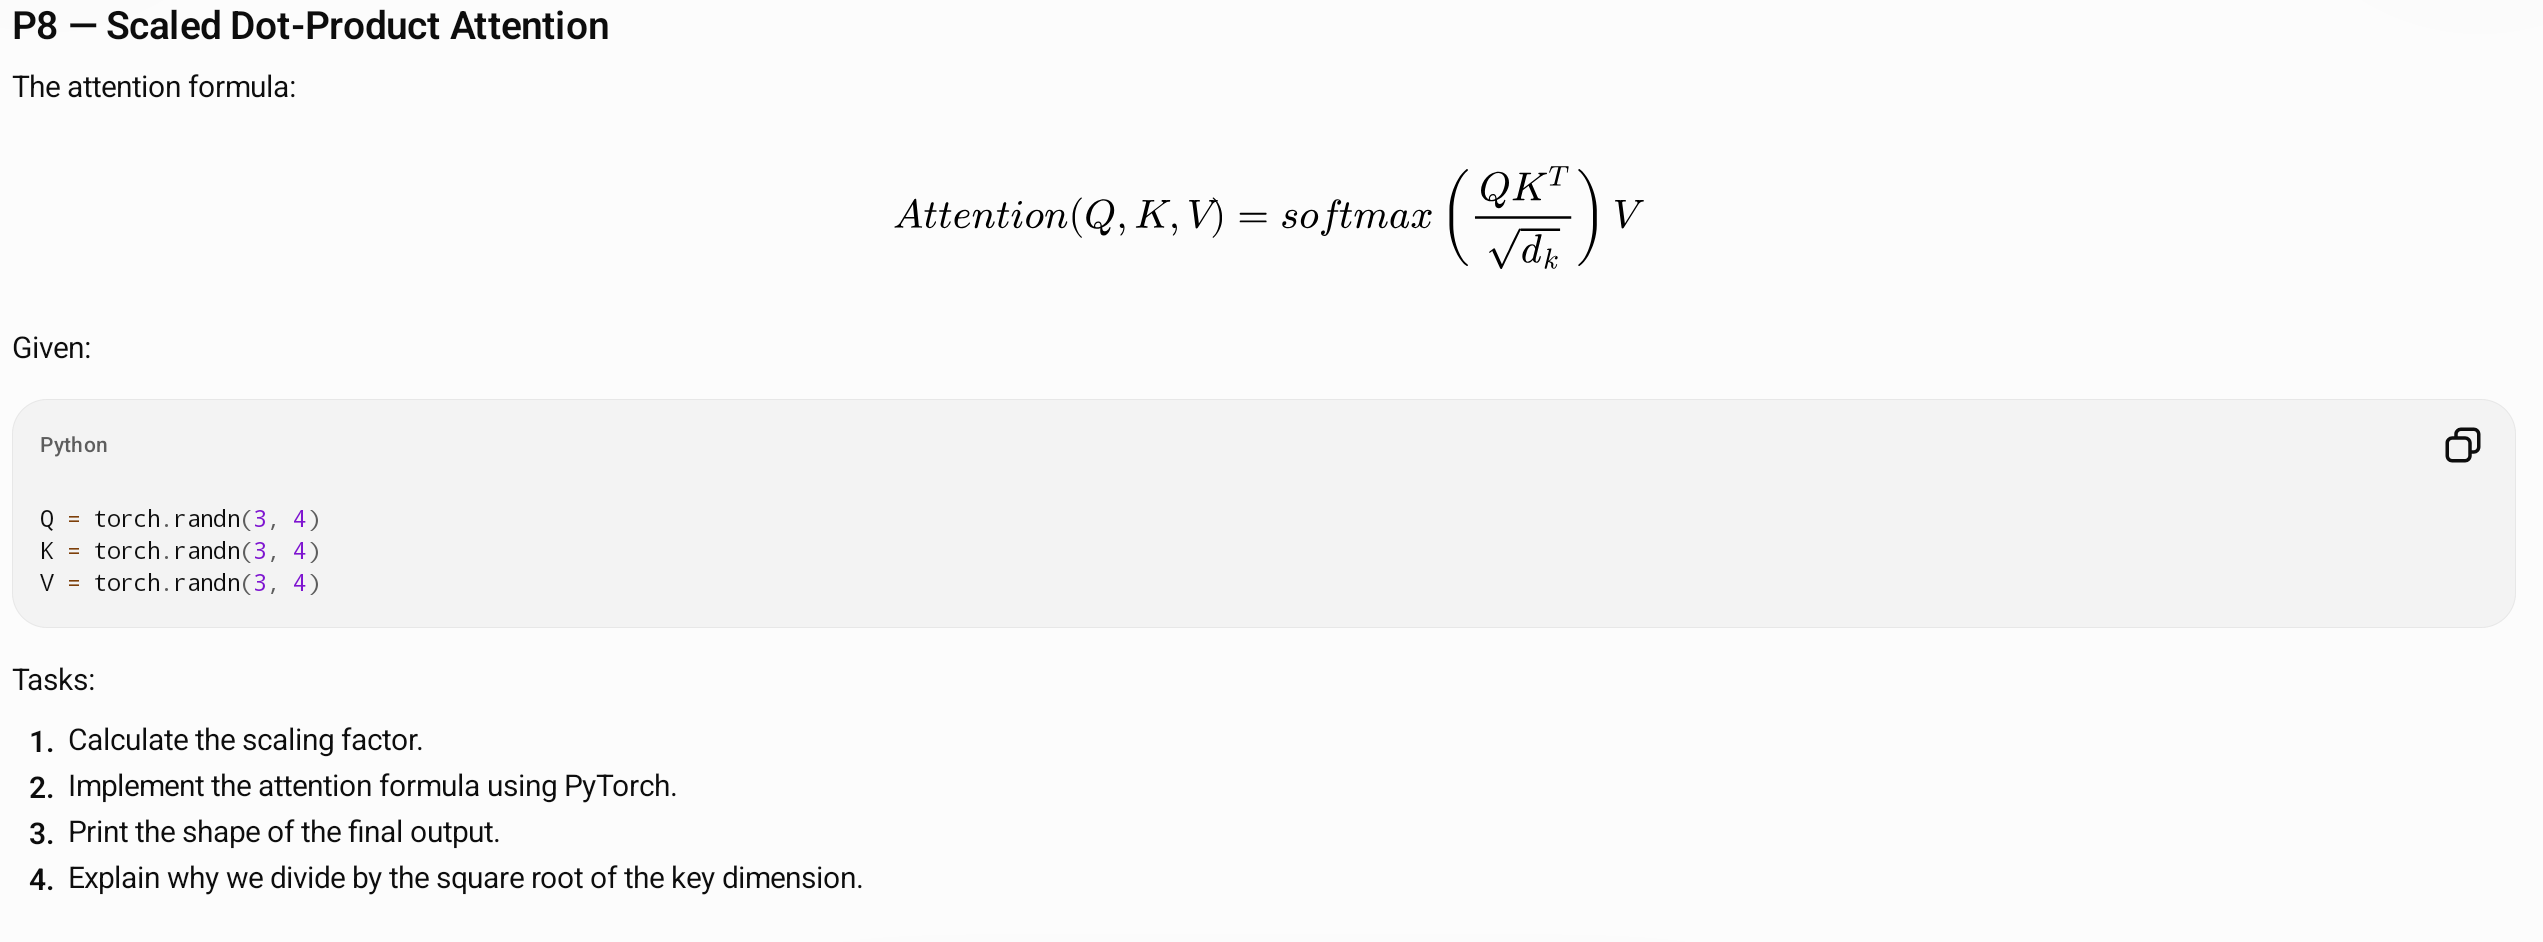

In [ ]:
import torch
import torch.nn.functional as F
Q=torch.randn(3,8)
K=torch.randn(3,8)
V=torch.randn(3,8)

d_k=K.shape[-1] #1
score=Q@K.T/torch.sqrt(torch.tensor(d_k))
attention_output=F.softmax(score,dim=-1) #2
attention_output=attention_output@V
print(attention_output)#3
#we dive by sqrt of key dimension because to make  suitable scale input for softmax if the dot product is too large then there is
#problem while training and adjusting weights during backpropagation

torch.Size([3, 8])


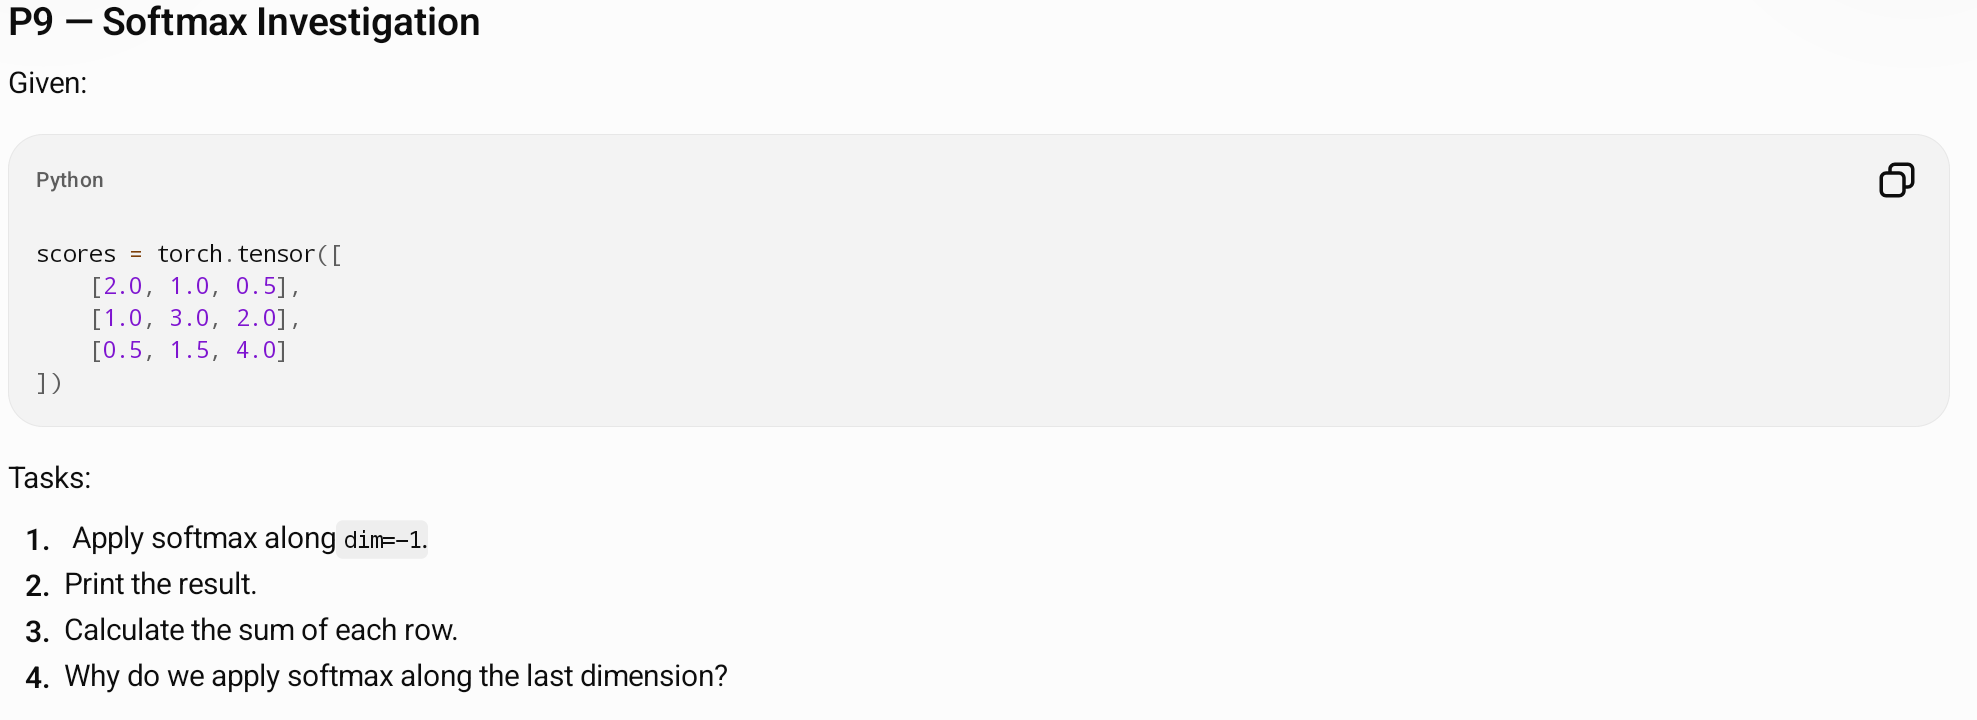

In [ ]:
import torch
import torch.nn.functional as F
scores = torch.tensor([
    [2.0, 1.0, 0.5],
    [1.0, 3.0, 2.0],
    [0.5, 1.5, 4.0]
])

attention=F.softmax(scores,dim=-1)
print(attention)


tensor([[0.6285, 0.2312, 0.1402],
        [0.0900, 0.6652, 0.2447],
        [0.0271, 0.0738, 0.8991]])


In [ ]:
print(attention.sum(dim=-1))
#we apply softmax along dim =-1 because to compare each query
# to aginst all keys if we use dim=0 then it like we comparing
#query to other query?

tensor([1.0000, 1.0000, 1.0000])


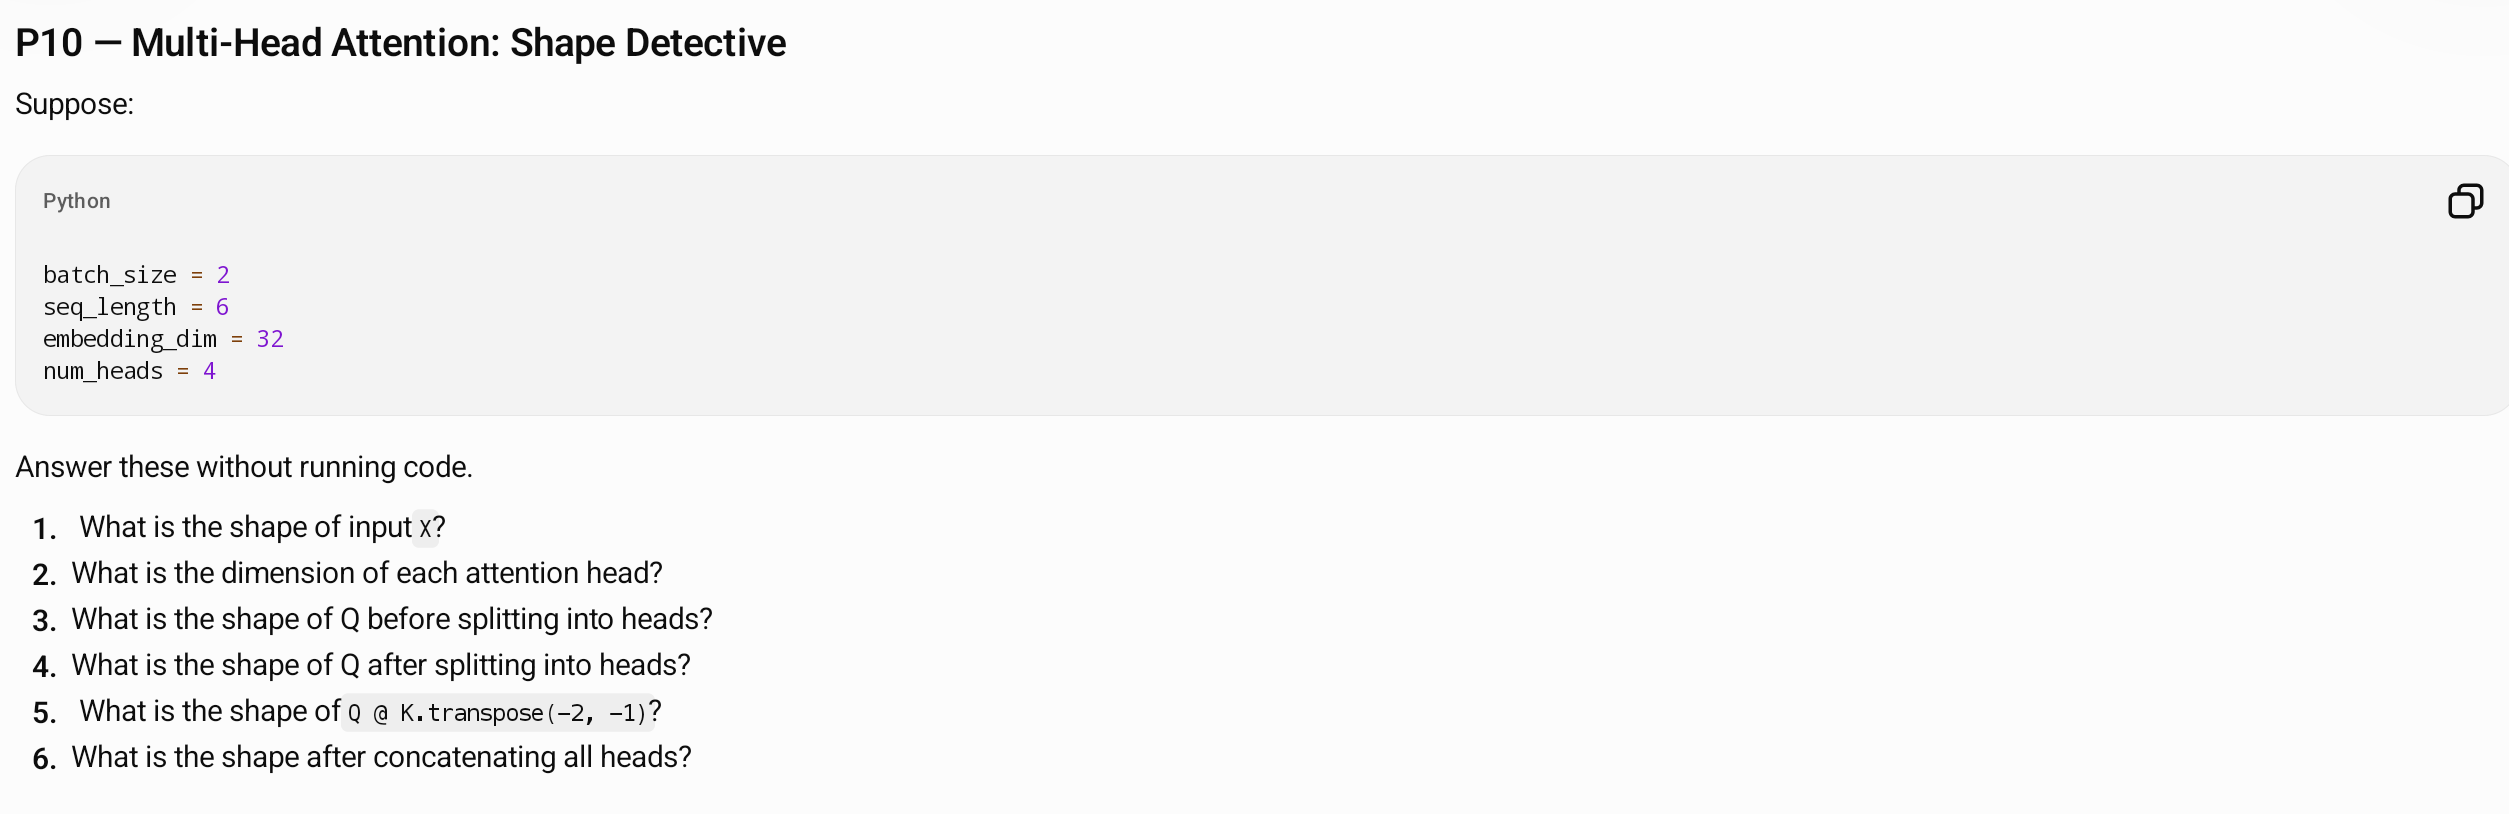

In [ ]:
# input shape (2,6,32)
#d_each_head=d_model/no_of_heads==32/4=8
#Q query  shape before splitting (2,6,32)
# Q for each head now shape (2,6,8) and splitted query shape (2,6,4,8)
#Q:(2,6,4,8) K:(2,6,4,8) K.T(-2,-1):❌❌❎❎
#all splitted hesds get combine w8th final shape (2,6,32)



Solution to 5th
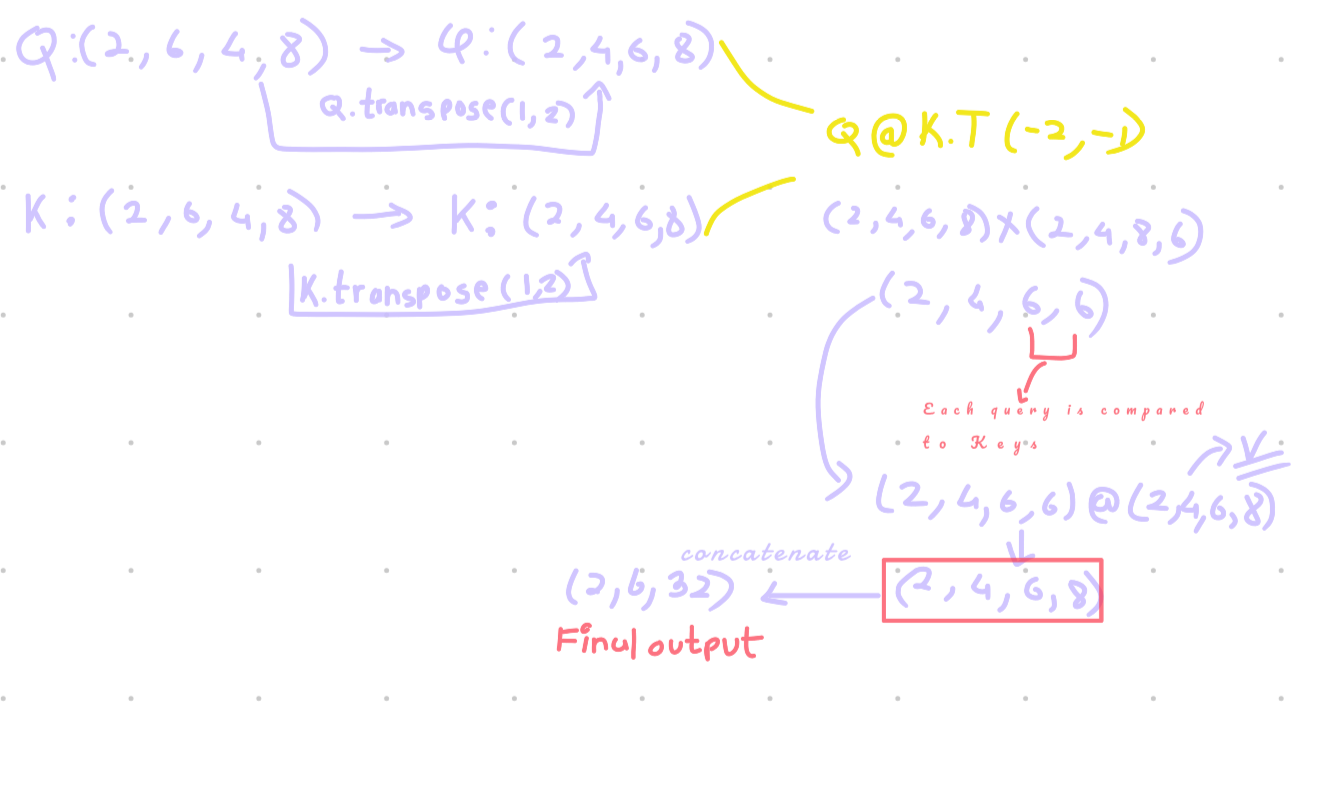

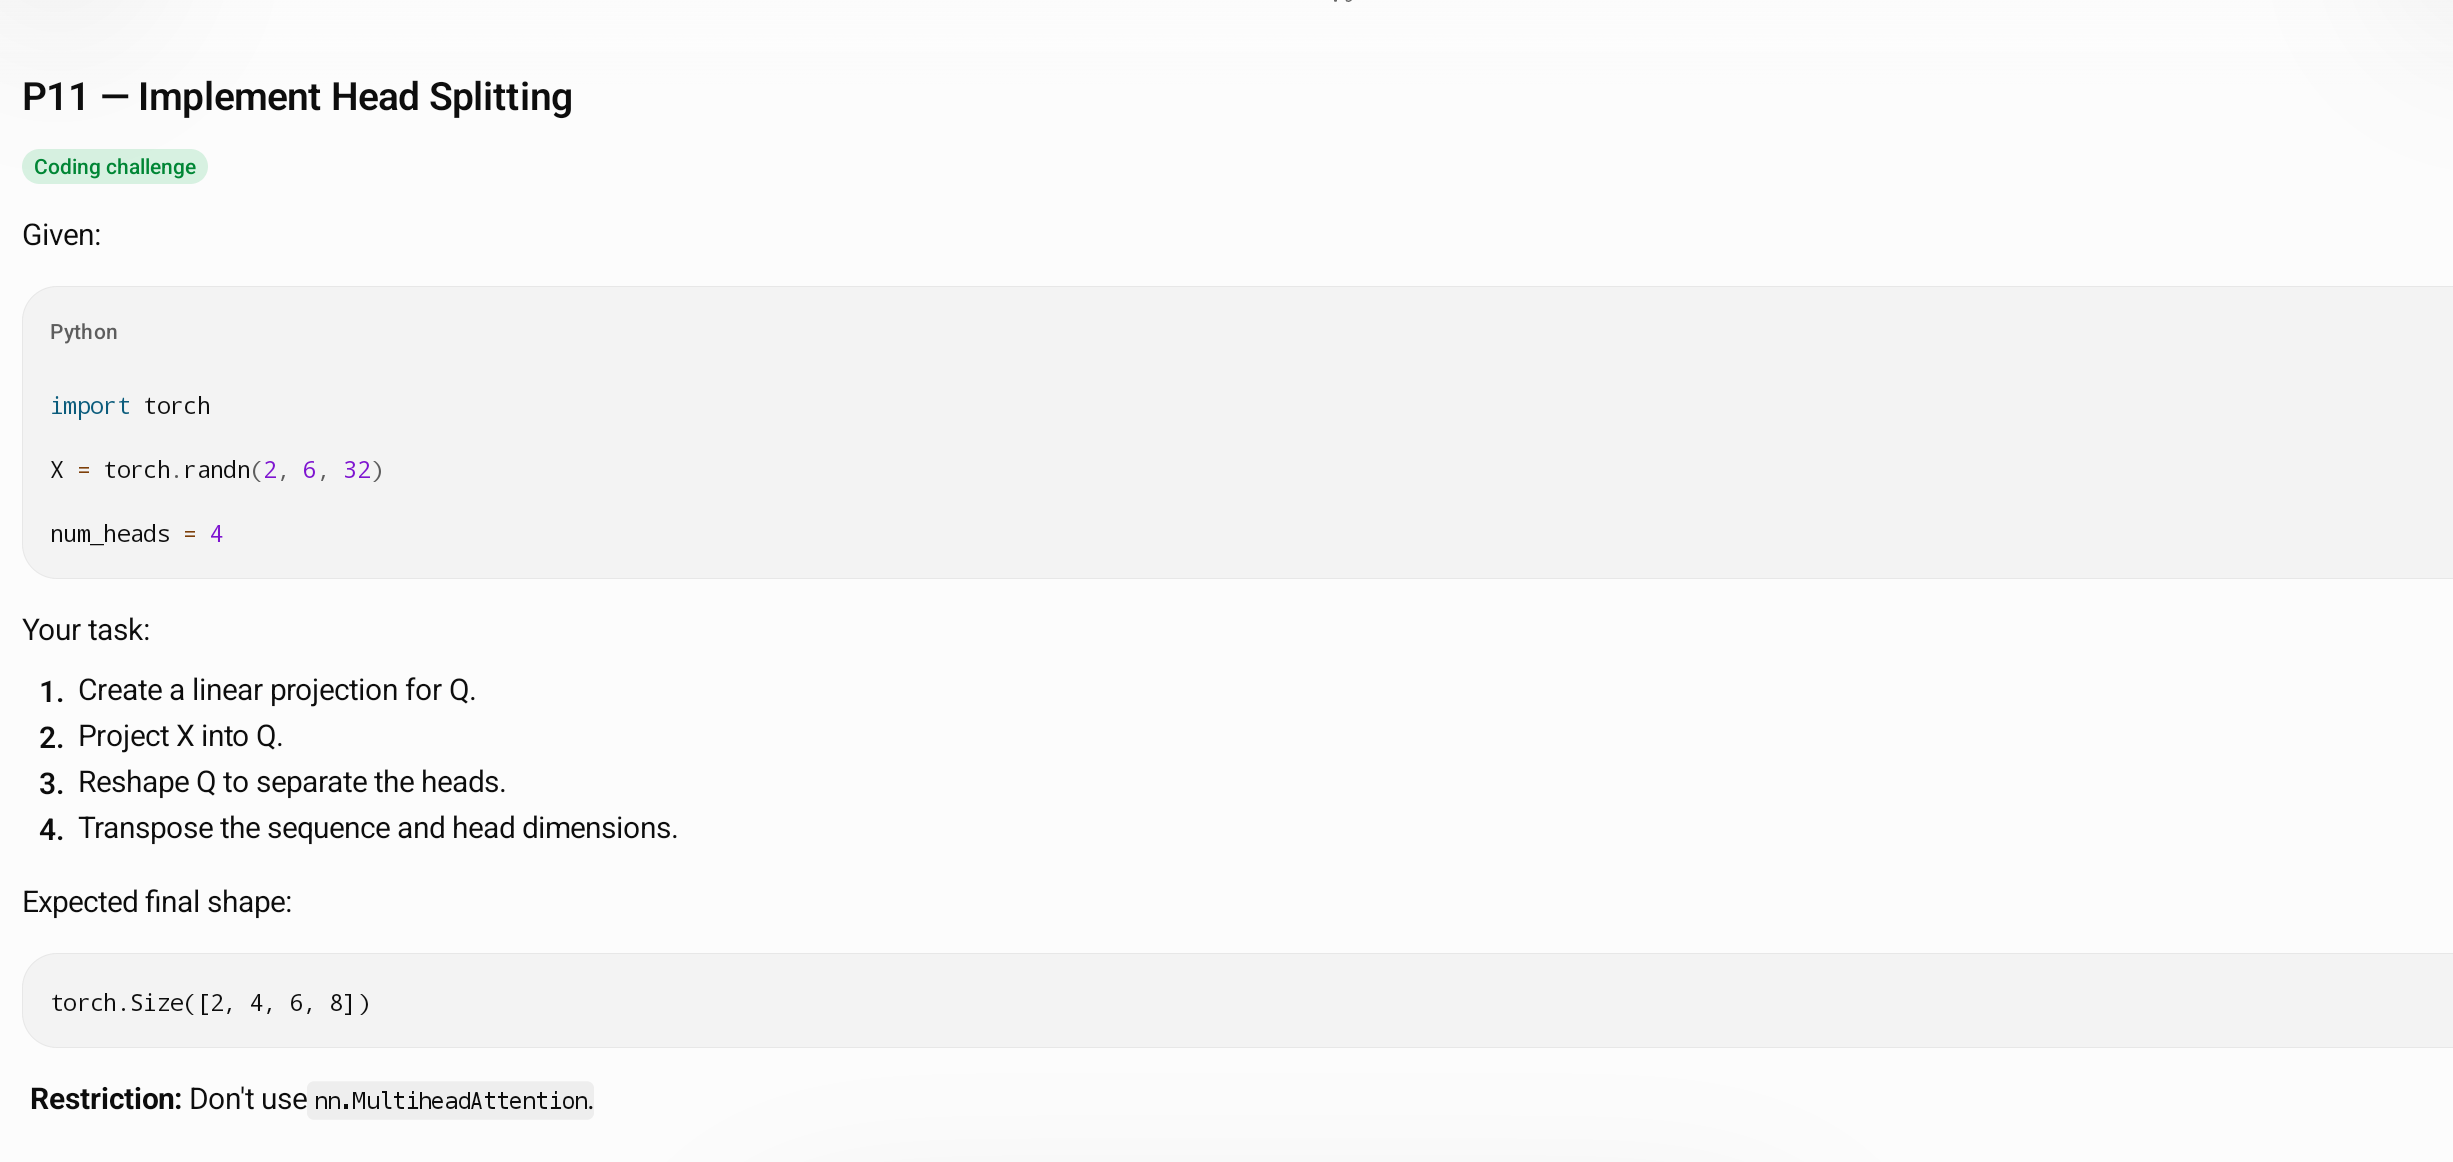

In [ ]:
import torch
num_heads=4
wq=torch.randn(32,32)
x=torch.randn(2,6,32)
Q=x@wq
Q=Q.reshape(2,4,6,8)

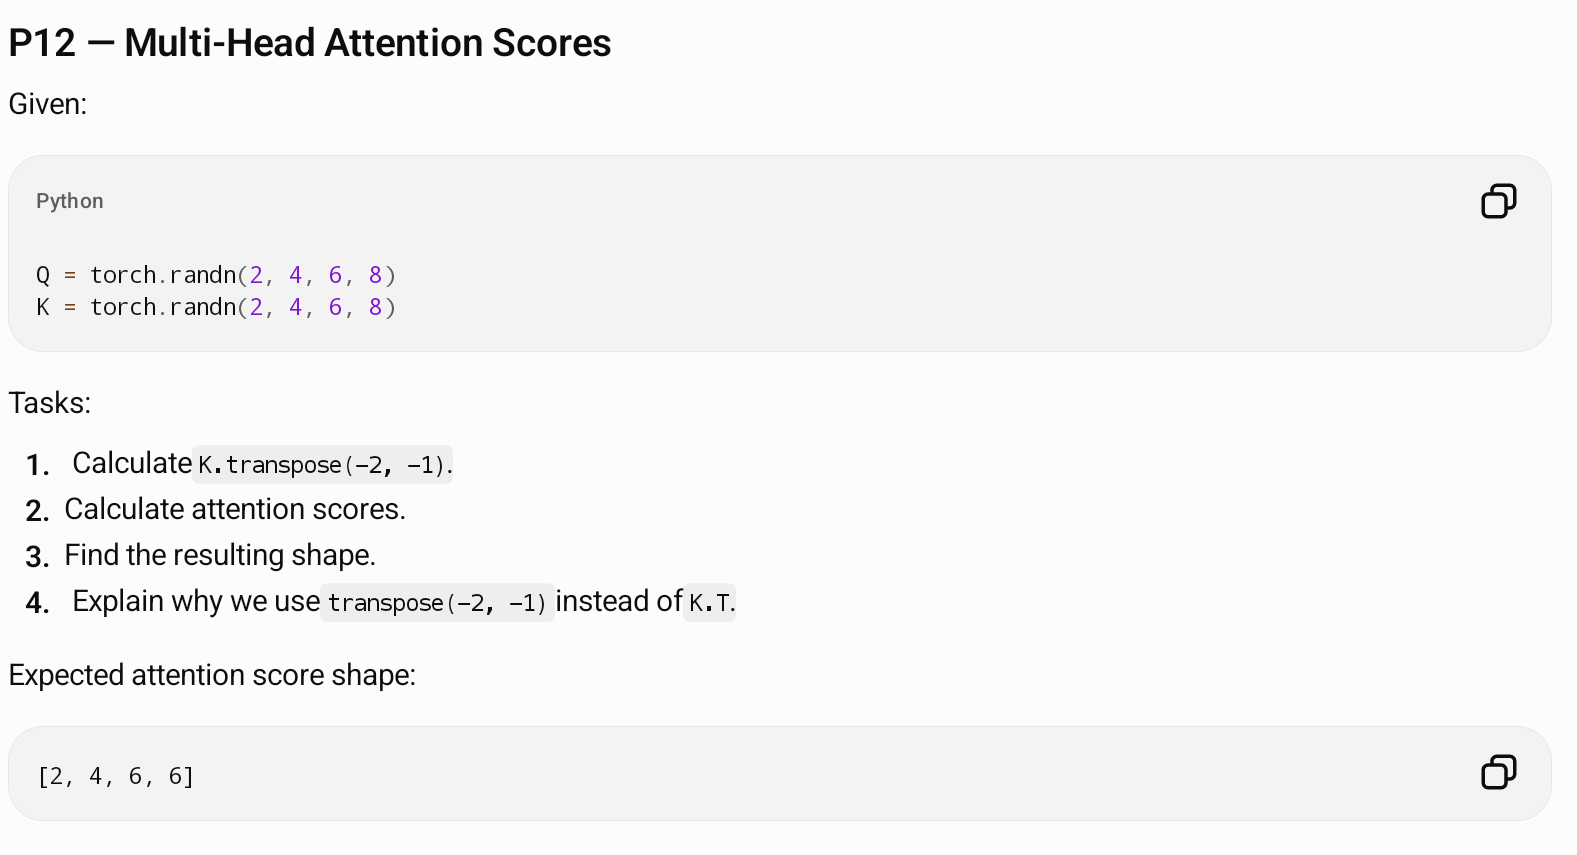

In [ ]:
import torch
q=torch.randn(2,4,6,8)
k=torch.randn(2,4,6,8)
score =q@k.transpose(-2,-1)
score#2

tensor([[[[  7.8097,  -1.2468,   0.0632,  -0.6831,  -3.8850,   5.6534],
          [  6.7779,  -0.6603,  -3.9675,   0.9215,  -0.3146,   1.8262],
          [ -0.9062,  -2.7415,  -0.7810,   1.8627,  -0.3334,  -1.8933],
          [ -2.3365,   1.2066,   0.5738,   1.4848,  -0.1666,  -4.3777],
          [  1.3363,  -1.2154,   1.4276,  -2.3652,  -3.6450,  -0.4243],
          [ -6.2961,   7.8294,   0.7233,  -0.5907,   3.3357,  -6.2313]],

         [[-11.3422,  -0.8757,  -4.5546,   4.7047,   0.9760,   0.4181],
          [ -2.8603,  -0.9057,  -3.7309,  -1.0424,   0.0205,  -0.4462],
          [ -0.1020,  -1.4478,  -2.1577,   0.9927,  -1.9180,  -3.5637],
          [ -4.3648,  -1.1712,   1.0004,   2.2436,   3.8764,   3.9653],
          [  2.6275,  -0.2850,  -0.1600,  -0.6094,   1.8983,   0.8575],
          [  4.0822,   0.9178,   6.9209,   1.0399,   1.4815,   1.2865]],

         [[ -0.6634,  -1.3537,   1.1765,  -1.2941,   0.0587,  -5.2223],
          [  0.9020,   4.2646,  -3.9411,  -3.4221,   1.4352,

In [ ]:
k.T.shape#4 look carefully we have to compare each q to k by using matrix multiplication
#q(2,4,6,8)@k(2,4,8,6) so we get resultig score(2,4,6,6)but we have k in shape of (2,4,6,8) if use k.T it by default transpose is (0,1) but we dont need it we need custom transpose to chnage 6,8 to 8,6
#so we going to use k.transpose(-2,-1)

torch.Size([8, 6, 4, 2])

In [ ]:
k.transpose(-2,-1).shape #1

torch.Size([2, 4, 8, 6])

In [ ]:
score.shape#3

torch.Size([2, 4, 6, 6])

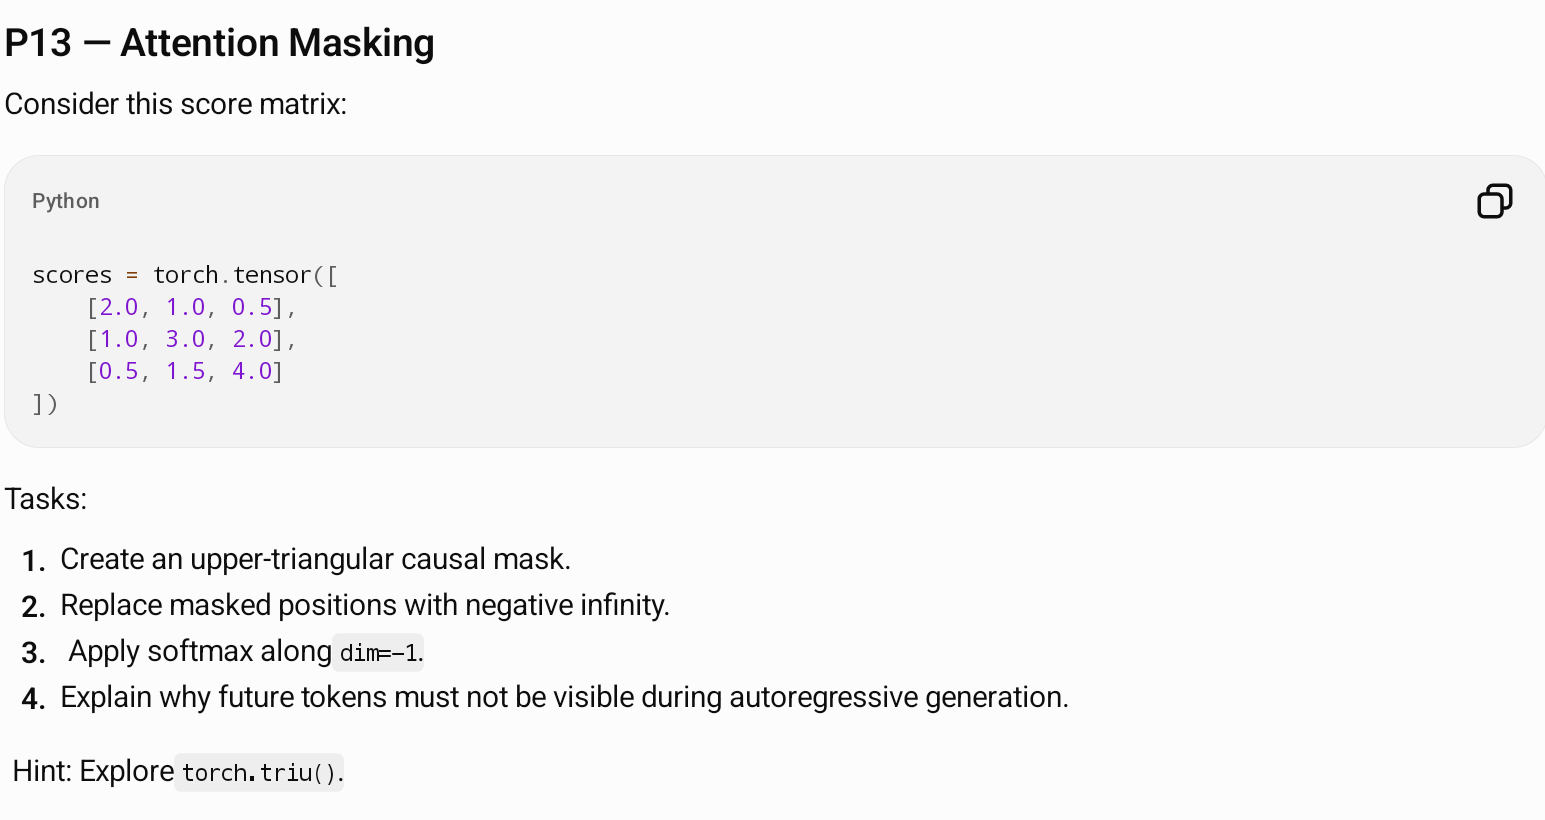

In [ ]:

import torch
import numpy as np

scores = torch.tensor([
    [2.0, 1.0, 0.5],
    [1.0, 3.0, 2.0],
    [0.5, 1.5, 4.0]
])

#1
upper_tri_casual_mask=np.triu(scores)

#2
row,column=torch.triu_indices(scores.shape[0],scores.shape[1],offset=1)
scores[row,column]=-torch.inf

#3
import torch.nn.functional as F
attention=F.softmax(scores,dim=-1)

#4
'''We use casual masking when generating token. ldel should focous on generating each token at a time if it can see future token then it will not able to generate a good
output to prompt it like information leakage
Example
suppose model is generating sequence
'I love inference'
it should generate first 'I'
THEN 'love'
THEN 'inferenfe'
while generating 'I' it should not have information of future token like 'inference'
📍if model get info of all token while generating 'I' then it is information leakage which is not good while training it.
'''



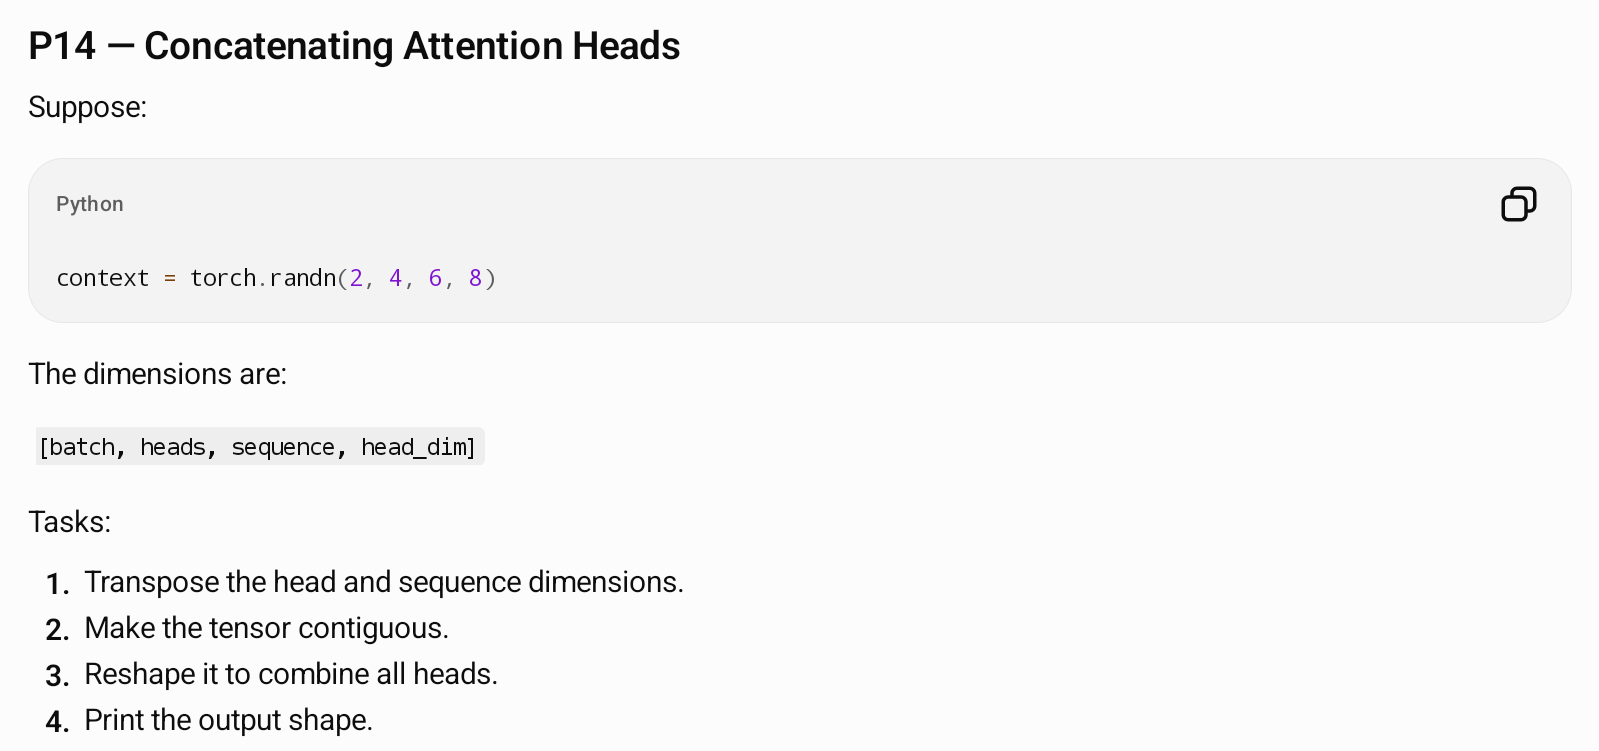

In [ ]:
import torch
cntxt=torch.randn(2,4,6,8)
#1
cntxt=cntxt.transpose(1,2)
#2,3,4
cntxt=cntxt.reshape(2,6,32)
cntxt.shape



torch.Size([2, 6, 32])

In [ ]:
cntxt

tensor([[[-1.0791e+00, -7.0065e-01, -5.8371e-02, -9.0449e-01, -1.3582e+00,
           9.8202e-01,  1.9745e-01,  3.3869e-01,  7.0597e-01,  5.5917e-01,
           1.2269e+00,  1.4656e-01, -1.6916e+00, -3.3512e-01,  1.4306e+00,
           9.1115e-01, -3.0708e-01,  1.1885e+00,  9.7782e-02,  8.6826e-01,
          -3.5269e-01, -2.3645e-01, -6.6397e-01,  1.6777e+00, -9.9758e-01,
          -3.0823e-01, -4.1876e-01,  6.8403e-01,  6.5745e-01, -7.7804e-02,
          -1.0533e+00,  5.4501e-01],
         [-7.1954e-01, -2.4765e+00,  3.1974e-01, -4.1983e-01, -6.8757e-02,
          -9.5254e-01,  8.1710e-01, -1.4002e+00, -8.3302e-01,  1.3713e+00,
          -1.2255e+00, -1.5738e+00,  1.5746e+00, -1.8464e+00, -5.5368e-03,
           2.3178e-01, -1.0577e+00, -1.2664e+00, -2.6801e-01,  3.6260e-01,
          -1.8798e+00, -1.4769e-01, -1.4403e+00,  6.3422e-01,  1.1905e+00,
          -1.4899e+00, -6.4133e-01, -9.8954e-01,  8.8090e-01,  8.7351e-01,
           8.3104e-01, -1.7502e+00],
         [ 1.3319e-01,  1.

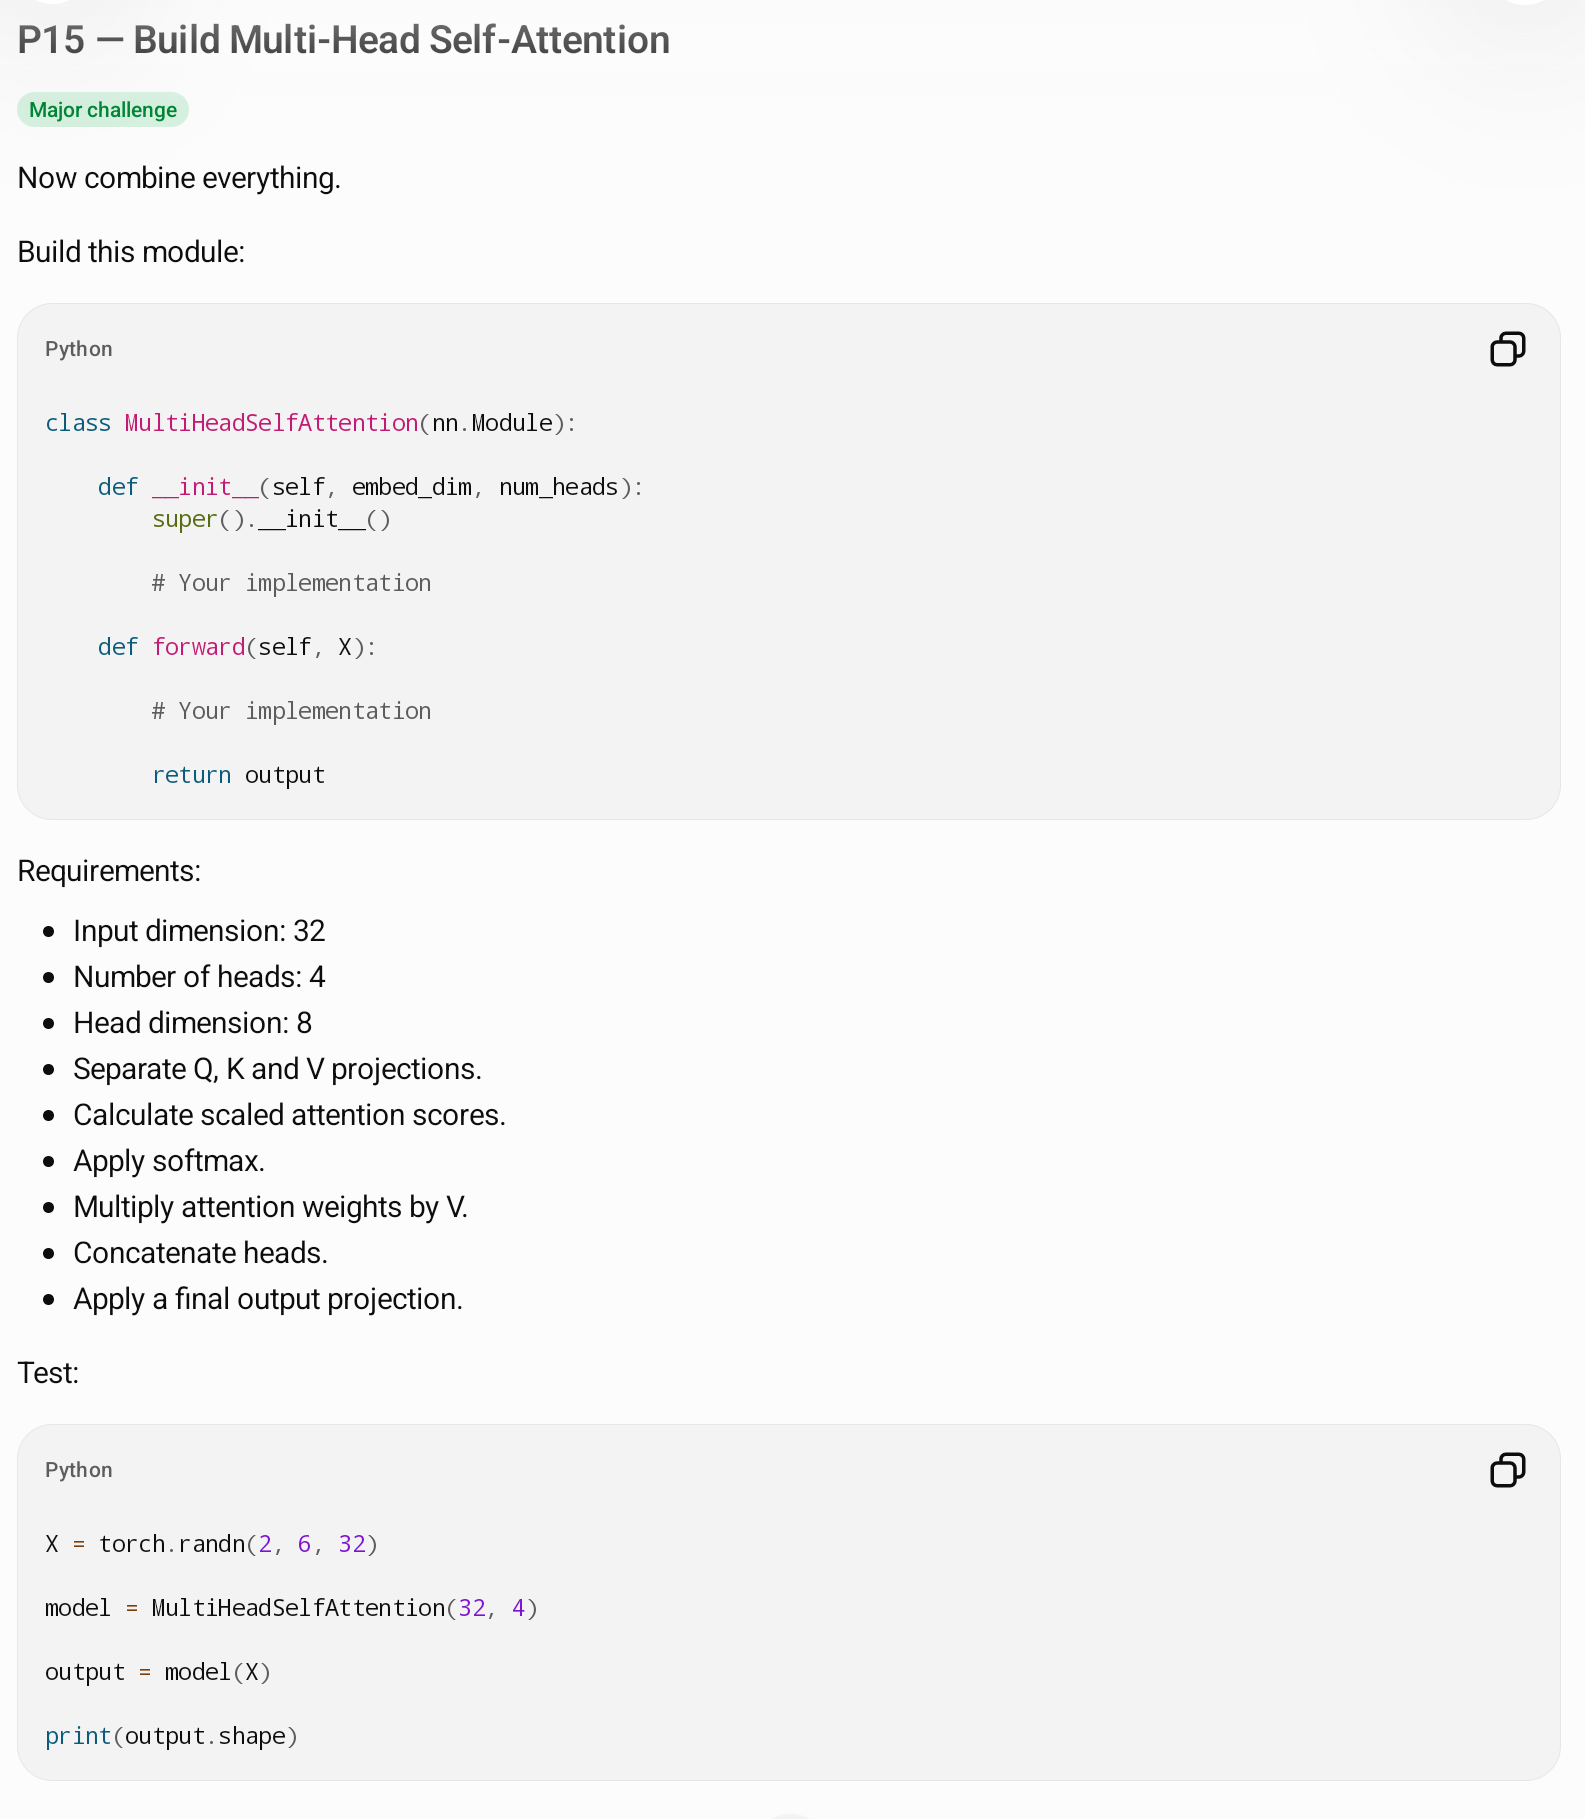

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class MultiHeadSelfAttention(nn.Module):

    def __init__(self, embed_dim, num_heads):
        super().__init__()

        self.embed_dim=embed_dim
        self.num_heads=num_heads
        self.head_dim=embed_dim//num_heads

        self.W_Q=nn.Linear(embed_dim,embed_dim)
        self.W_K=nn.Linear(embed_dim,embed_dim)
        self.W_V=nn.Linear(embed_dim,embed_dim)
        self.W_O=nn.Linear(embed_dim,embed_dim)



    def forward(self, X):

        b,s,e=X.shape


        q=self.W_Q(X)
        k=self.W_K(X)
        v=self.W_V(X)

        Q=q.reshape(b,s,self.num_heads,self.head_dim)
        K=k.reshape(b,s,self.num_heads,self.head_dim)
        V=v.reshape(b,s,self.num_heads,self.head_dim)

        Q=Q.transpose(1,2)
        K=K.transpose(1,2)
        V=V.transpose(1,2)

        attention_score=Q@K.transpose(-2,-1)/torch.sqrt(torch.tensor(self.head_dim))
        attention=F.softmax(attention_score,dim=-1)
        output=attention@V
        output=output.transpose(1,2)
        output=output.reshape(b,s,e)
        output=self.W_O(output)




        return output

In [ ]:
X=torch.randn(2,6,32)
model=MultiHeadSelfAttention(32,4)
output=model(X)


/tmp/ipykernel_890/1261331967.py:39: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  attention=F.softmax(attention_score)


In [ ]:
X #input

tensor([[[ 2.7695e+00,  1.3235e+00,  1.2756e+00, -1.0306e+00,  4.5772e-01,
          -1.2900e+00, -4.9131e-01, -8.2649e-01, -1.0976e+00, -3.9175e-01,
          -6.6522e-01,  3.8075e-01, -1.4037e-01, -1.2293e+00, -1.0651e+00,
           9.4131e-01, -4.8606e-02, -7.9360e-01, -8.0955e-01,  6.6648e-01,
          -7.7208e-01,  5.6853e-01,  1.5310e+00, -1.6719e+00, -4.0383e-01,
          -5.2063e-01,  3.2484e-03, -1.7568e+00, -1.4877e+00,  1.1848e+00,
           2.1064e+00,  7.3336e-02],
         [-1.1271e+00, -5.1458e-01,  1.2906e+00,  2.9670e-01, -3.1868e-01,
          -4.7642e-01, -1.7615e-01,  1.0595e+00, -2.2415e+00, -4.7131e-01,
           5.8345e-01, -1.1353e+00, -1.0314e+00,  6.5418e-01, -8.6059e-01,
          -1.6443e-01,  1.7843e-01, -1.7382e+00, -3.8619e-01, -2.1470e-01,
          -3.0075e-01,  1.5546e+00, -1.2518e+00,  8.5787e-01, -1.3446e+00,
           9.9704e-01, -1.2669e+00,  5.6192e-01, -1.5052e-01,  1.0126e+00,
           4.6486e-01,  1.1320e+00],
         [ 1.3469e-01,  2.

In [ ]:
print(output.shape,output)

torch.Size([2, 6, 32]) tensor([[[ 0.0482,  0.4300, -0.0115,  0.3354, -0.1682, -0.2621,  0.2735,
           0.4041, -0.5506,  0.2942, -0.0444,  0.3069,  0.0602,  0.1374,
           0.2603,  0.0134, -0.1783,  0.2025, -0.2088, -0.1487, -0.2209,
           0.1683,  0.0622,  0.1148, -0.0886,  0.0572, -0.1900, -0.3470,
          -0.1186, -0.4027, -0.0475, -0.1790],
         [ 0.0151,  0.3598, -0.0465,  0.3562, -0.1454, -0.2765,  0.4027,
           0.3659, -0.5783,  0.3677, -0.0187,  0.2595,  0.0139,  0.1583,
           0.2626,  0.0384, -0.1492,  0.1649, -0.0995, -0.1374, -0.2785,
           0.1548,  0.1353,  0.0556, -0.1538,  0.0285, -0.2344, -0.3117,
          -0.1859, -0.4018, -0.1346, -0.3065],
         [ 0.0429,  0.3543, -0.0056,  0.4538, -0.2014, -0.1869,  0.3183,
           0.2234, -0.5087,  0.3477,  0.0102,  0.1904, -0.0360,  0.0570,
           0.2587, -0.0195, -0.1599,  0.1645,  0.0123, -0.1584, -0.2122,
           0.2697,  0.1585, -0.0185, -0.2381,  0.0126, -0.1782, -0.1927,
       

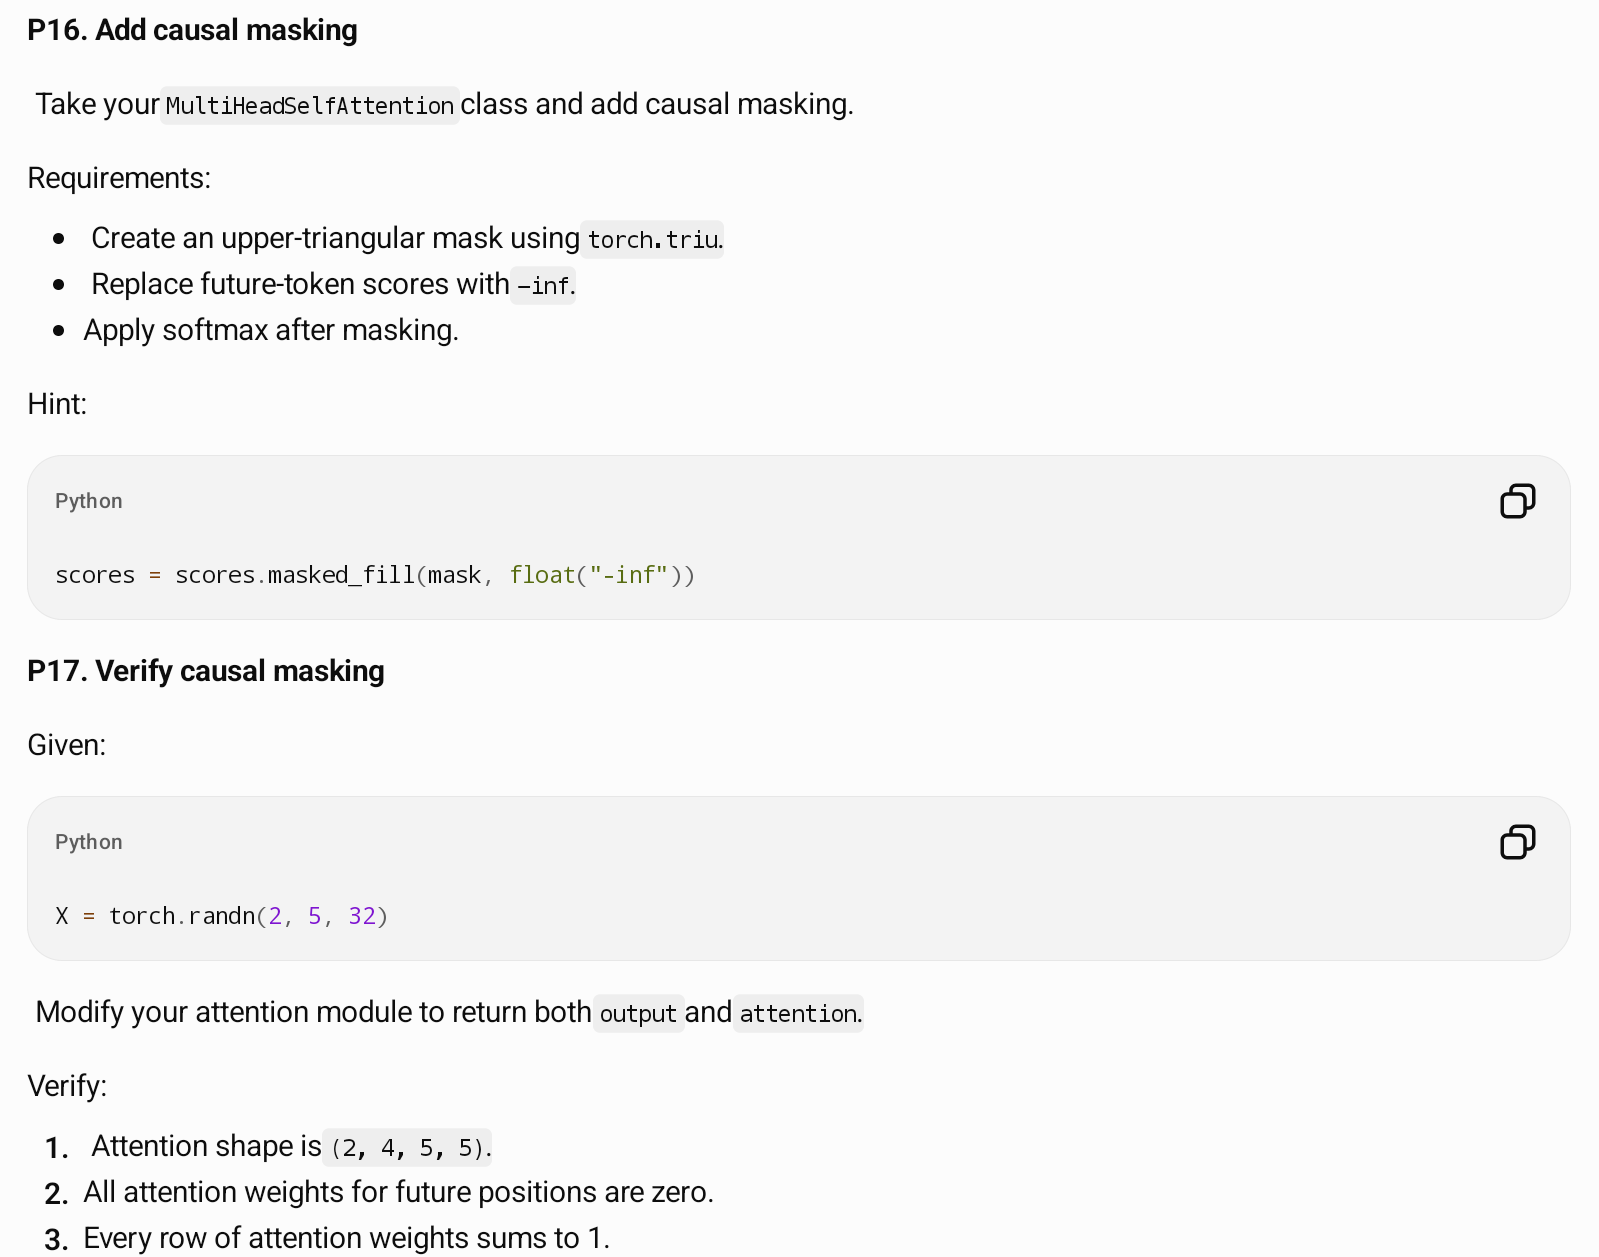

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MultiHeadSelfAttention(nn.Module):

    def __init__(self, embed_dim, num_heads):
        super().__init__()

        self.embed_dim=embed_dim
        self.num_heads=num_heads
        self.head_dim=embed_dim//num_heads

        self.W_Q=nn.Linear(embed_dim,embed_dim)
        self.W_K=nn.Linear(embed_dim,embed_dim)
        self.W_V=nn.Linear(embed_dim,embed_dim)
        self.W_O=nn.Linear(embed_dim,embed_dim)


    def forward(self, X):

        b,s,e=X.shape


        q=self.W_Q(X)
        k=self.W_K(X)
        v=self.W_V(X)

        Q=q.reshape(b,s,self.num_heads,self.head_dim)
        K=k.reshape(b,s,self.num_heads,self.head_dim)
        V=v.reshape(b,s,self.num_heads,self.head_dim)

        Q=Q.transpose(1,2)
        K=K.transpose(1,2)
        V=V.transpose(1,2)

        attention_score=Q@K.transpose(-2,-1)/torch.sqrt(torch.tensor(self.head_dim))


        #16
        mask=torch.triu(torch.ones(s,s,device=X.device,dtype=torch.bool),diagonal=1)
        attention_score=attention_score.masked_fill(mask,float("-inf"))

        attention=F.softmax(attention_score,dim=-1)
        future_weights=torch.triu(attention,diagonal=1)
        output=attention@V
        output=output.transpose(1,2)
        output=output.reshape(b,s,e)
        output=self.W_O(output)


        return output,attention,future_weights


In [ ]:
#17

X=torch.randn(2,5,32)
model=MultiHeadSelfAttention(32,4)
output,attention,future_weights=model(X)



In [ ]:
print(attention.shape)#17.1


torch.Size([2, 4, 5, 5])


In [ ]:
print(torch.allclose(future_weights,torch.zeros_like(future_weights)))#17.2

True


In [ ]:
rs=attention.sum(dim=-1)#17.3
rs

tensor([[[1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
         [1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
         [1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
         [1.0000, 1.0000, 1.0000, 1.0000, 1.0000]],

        [[1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
         [1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
         [1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
         [1.0000, 1.0000, 1.0000, 1.0000, 1.0000]]], grad_fn=<SumBackward1>)

In [ ]:
output

tensor([[[-3.2826e-02,  2.3747e-01,  2.1177e-01, -1.7500e-01, -3.1119e-01,
           1.9398e-01, -4.6272e-02,  4.7572e-01,  1.9524e-01, -2.2294e-02,
          -2.7151e-01,  2.5028e-01, -4.9441e-01,  9.5203e-02, -3.3276e-02,
          -3.8167e-01,  3.9970e-01,  5.0480e-02,  2.2281e-01,  4.4685e-01,
          -5.7348e-02,  2.5435e-02,  2.3925e-01, -2.4034e-01,  3.7209e-01,
          -4.0935e-01, -2.1419e-01, -3.2338e-01,  3.9524e-02, -2.4222e-01,
          -4.8841e-02, -5.1454e-02],
         [-1.7258e-01, -7.6397e-02,  4.2006e-01,  9.9033e-02, -1.6565e-01,
          -2.8607e-02, -4.5980e-02,  3.7718e-01,  1.0509e-01,  9.9687e-02,
           1.0665e-01, -3.8392e-02, -3.2959e-01,  1.6649e-02, -2.2732e-01,
          -3.4893e-01,  1.5983e-01, -3.1517e-01,  2.6032e-01,  3.4079e-01,
          -2.9886e-01, -1.8643e-01, -3.5269e-02,  2.1428e-02,  2.3234e-01,
          -8.2227e-02, -4.9115e-02, -4.4249e-01, -2.2144e-01, -3.8110e-01,
          -4.7230e-01,  1.3379e-01],
         [-2.1020e-01, -1.

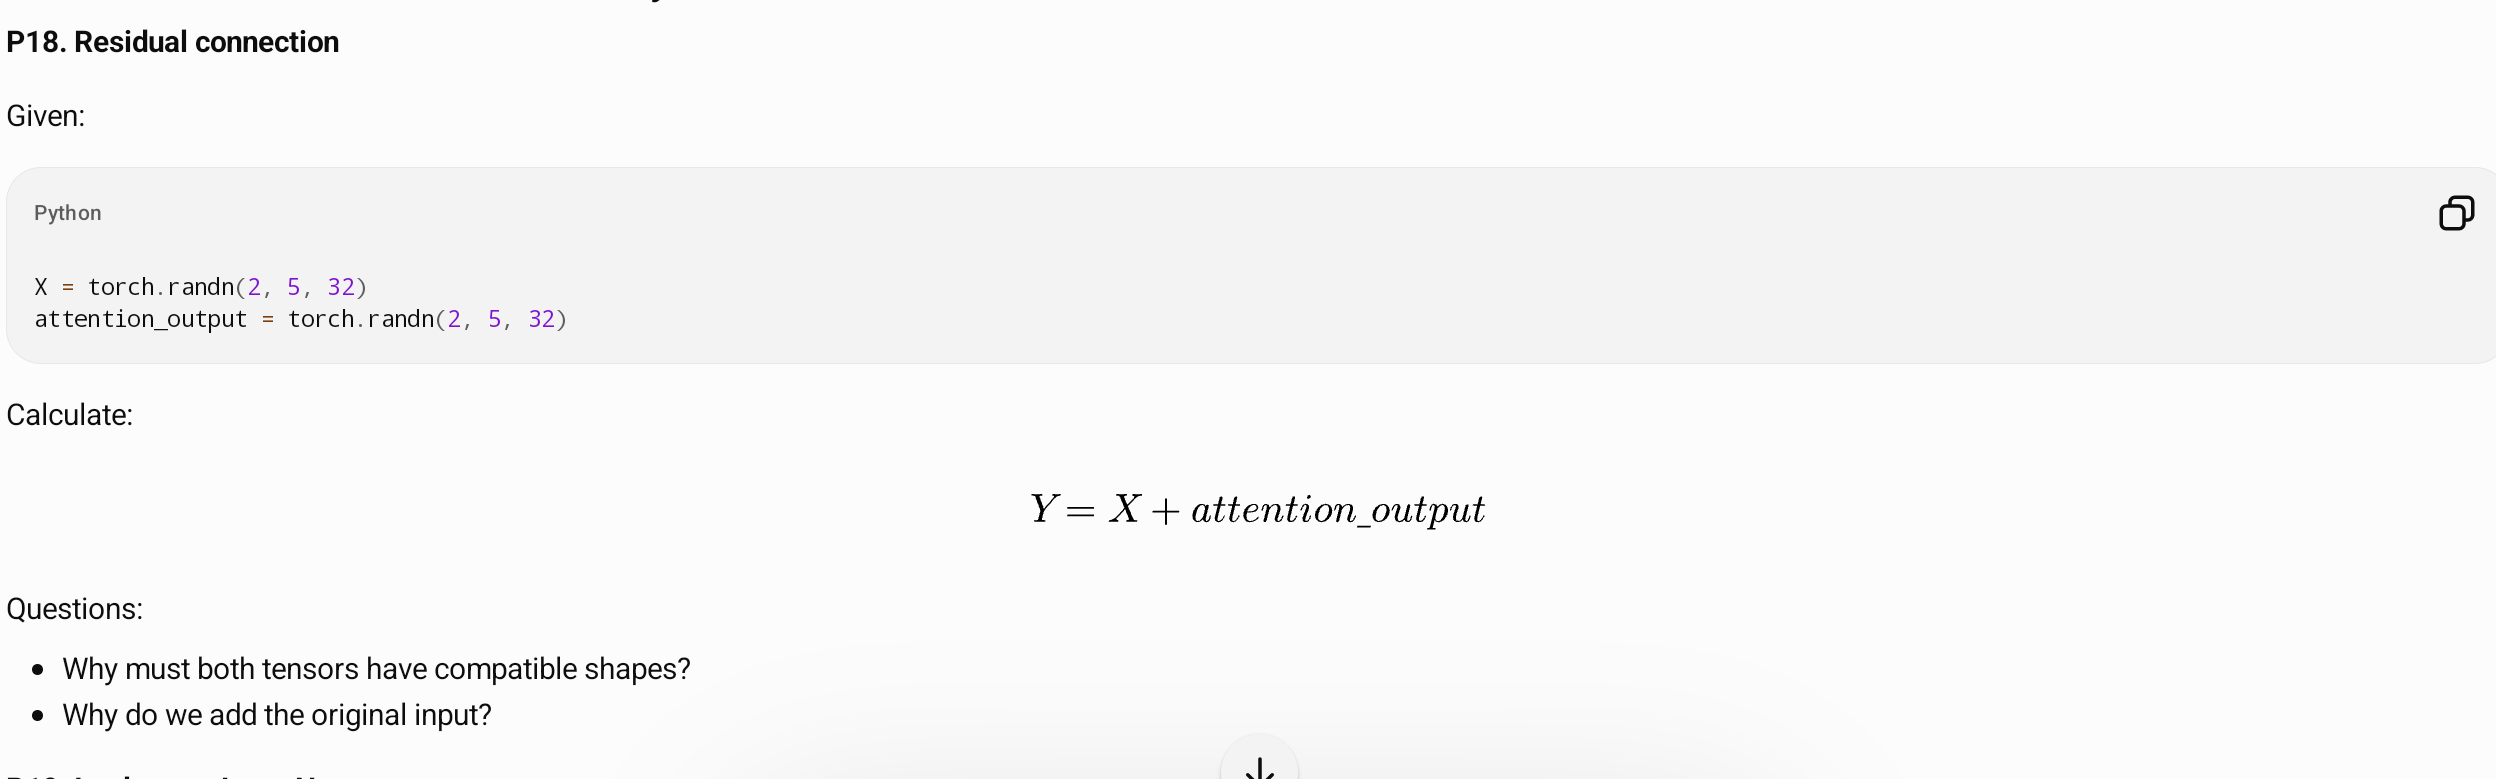

In [ ]:
import torch
X=torch.randn(2,5,32)
attention_output=torch.randn(2,5,32)
Y=X+attention_output

#1
'''if tensor do not have compatible shape then they cannot be added '''


#2
''' we add original output to store more information about each token so model can understand context more better'''
Y

tensor([[[ 1.3811,  0.3208,  0.1570,  0.5117, -0.0508, -3.1367, -0.8013,
           0.7589, -0.2727, -0.1657,  0.6461, -0.8392,  0.2338,  1.0888,
          -0.0845,  0.8718, -0.7836, -1.5877,  1.9402, -1.5316,  0.4441,
           2.6433, -1.9515, -1.1517, -0.1455, -0.2506,  0.5187,  0.1012,
           0.6777,  1.0927,  0.6862, -0.6099],
         [-1.9209,  1.0764,  0.5516, -1.1521,  1.1309, -1.5183, -0.7059,
           0.8314,  0.7871, -0.6786,  0.2291, -2.0811,  0.1787, -0.7327,
          -0.1463,  1.1665,  0.4127, -0.3788,  0.1083,  1.4122,  1.1733,
           2.2797,  2.5319,  0.9588, -0.5608,  2.0972,  0.6396,  0.9601,
          -0.0834, -1.1147,  0.4679,  1.3521],
         [ 1.9853,  1.7683,  1.3146, -1.0601,  0.8711,  0.4266,  2.0290,
           0.5544, -2.0157, -0.6962, -3.2374, -0.3950,  4.0382,  1.6194,
          -2.3319,  0.4945, -1.9600,  1.1388, -0.0619, -0.2622, -1.1826,
          -1.1115,  0.2104, -2.4700, -0.4415,  1.3658,  1.3867, -1.1307,
           1.5244, -0.7687,  4

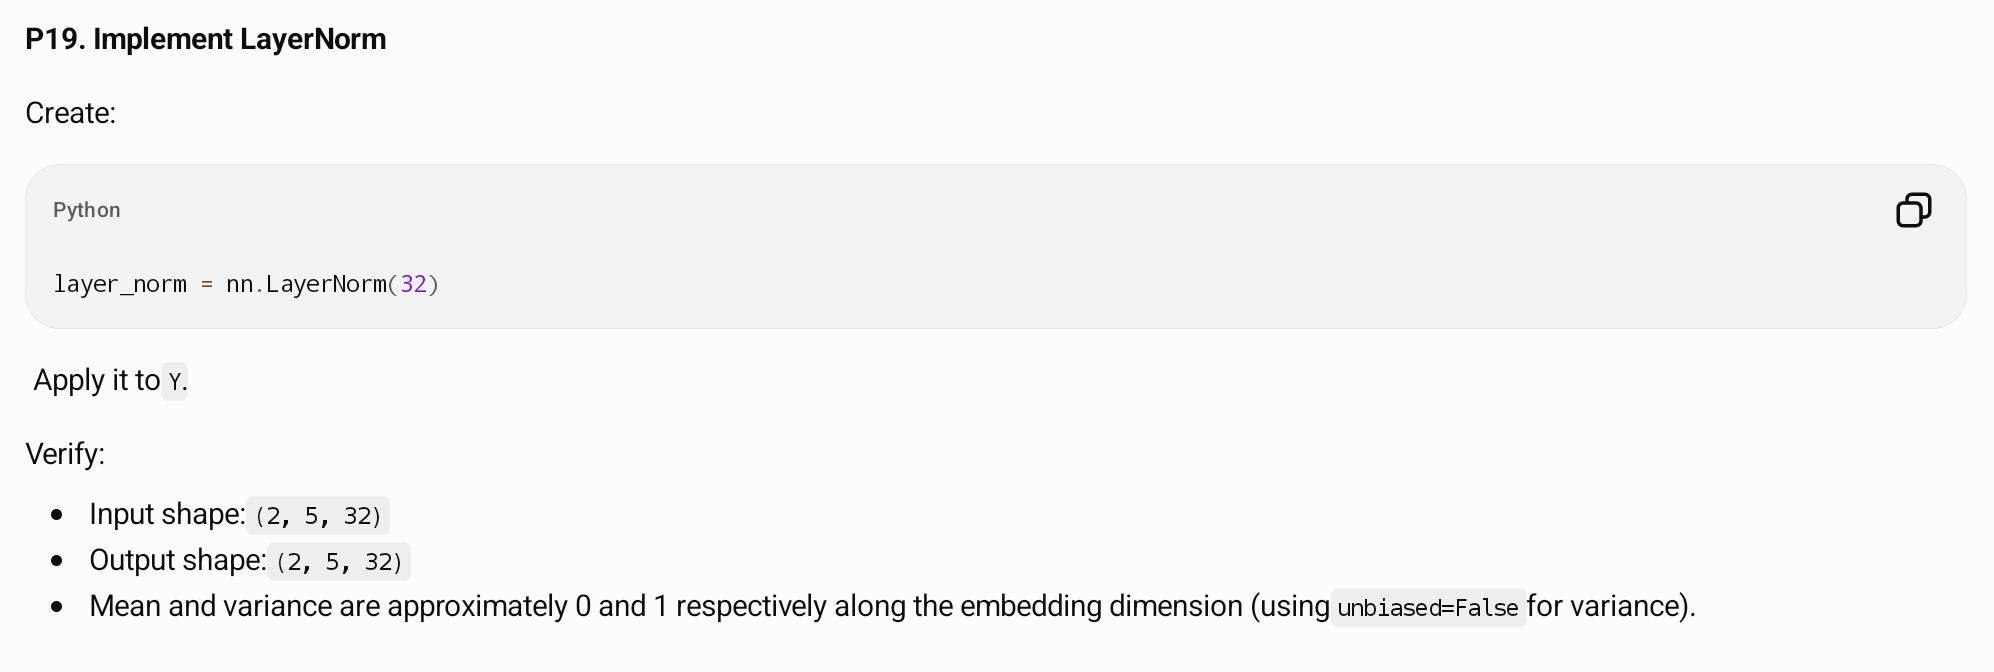

In [ ]:
import torch.nn as nn
layer_norm=nn.LayerNorm(32)
output=layer_norm(Y)

In [ ]:
#1
Y.shape

torch.Size([2, 5, 32])

In [ ]:
output.shape#2

torch.Size([2, 5, 32])

In [ ]:
output.mean(dim=-1)#3

tensor([[ 0.0000e+00, -2.2352e-08, -1.4901e-08,  2.7940e-08, -2.7474e-08],
        [ 1.4901e-08, -1.4901e-08,  7.4506e-09, -1.4901e-08, -3.4459e-08]],
       grad_fn=<MeanBackward1>)

In [ ]:
output.var(dim=-1,unbiased=False)

tensor([[1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000, 1.0000, 1.0000]], grad_fn=<VarBackward0>)

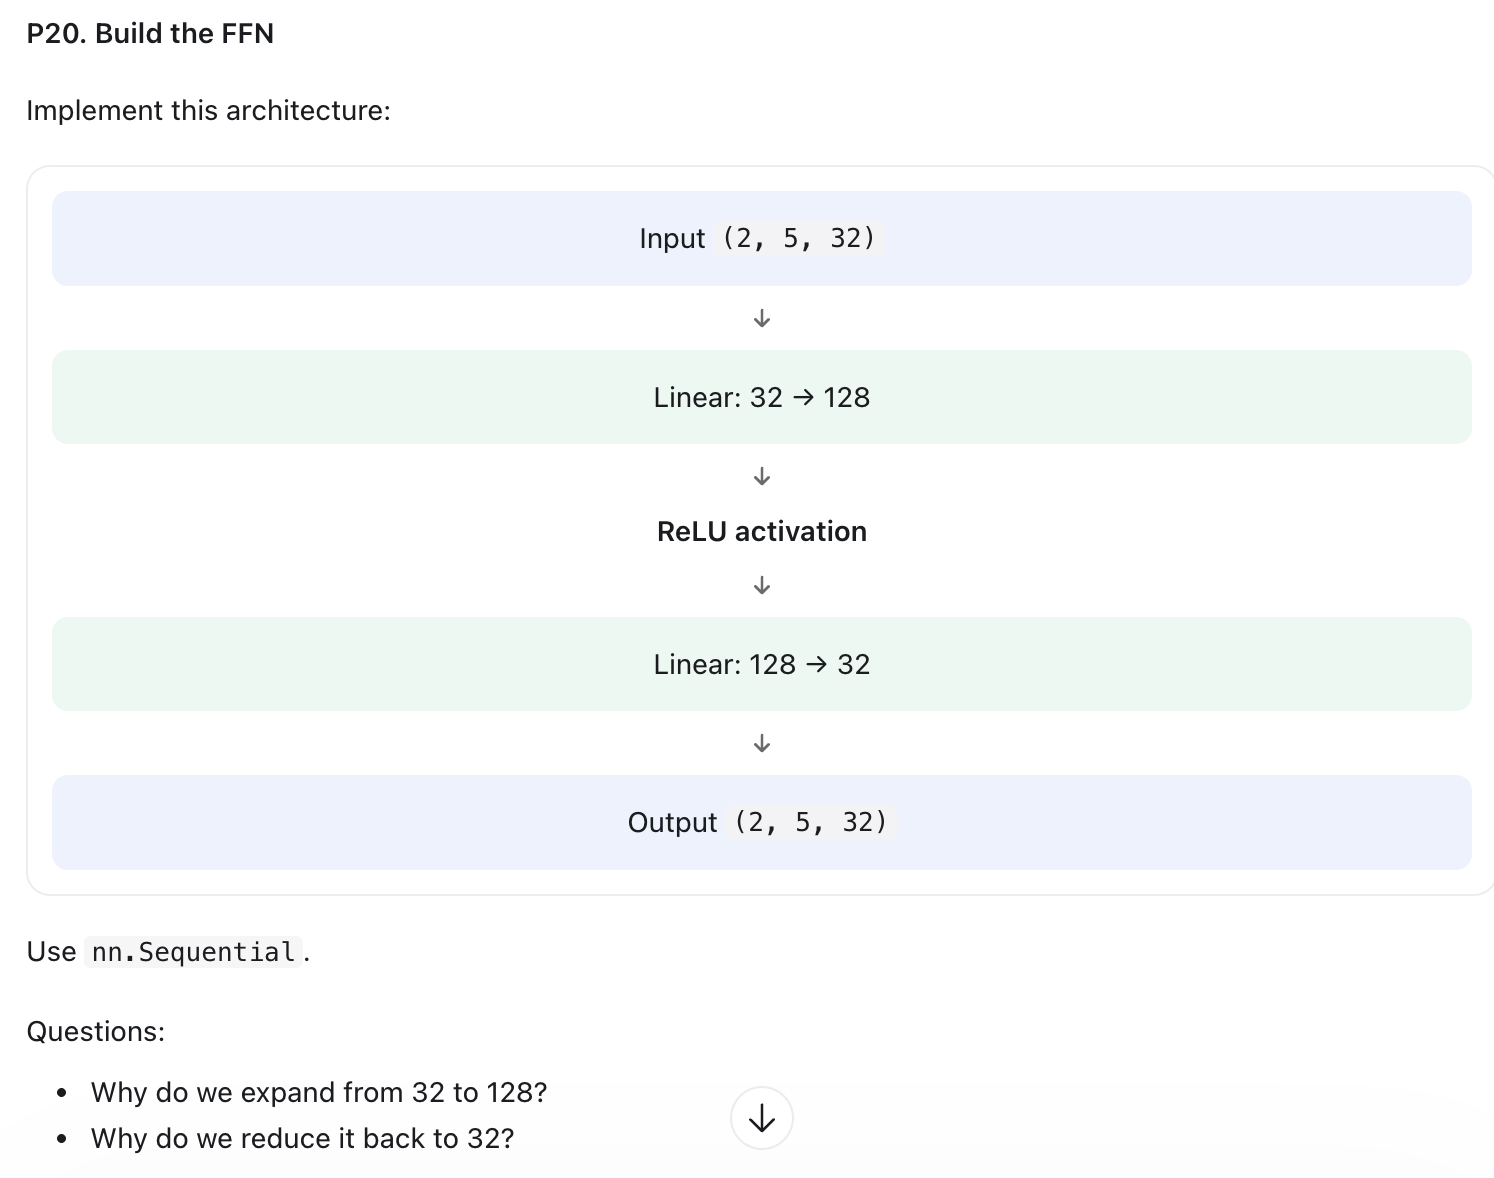

In [1]:
import torch
import torch.nn as nn

X=torch.randn(2,5,32)


ffn=nn.Sequential(
    nn.Linear(32,128),
    nn.ReLU(),
    nn.Linear(128,32)
)
ffn_output=ffn(X)
ffn_output
#1) we expand embeddinding dim from 32 to 128 because to it allows to learn more complex relations of each token it like providing wider space to learn
#2)but our original dimension is 32 after learning complex relations we have to compress it backkk

tensor([[[-0.1784, -0.2198, -0.2592,  0.3066,  0.1766,  0.0165,  0.0960,
          -0.3560,  0.0854, -0.1189,  0.0169,  0.1941,  0.3059,  0.1226,
          -0.0173,  0.2814,  0.4424,  0.3049, -0.0292, -0.1445, -0.0233,
           0.4314,  0.2500, -0.1945,  0.4405,  0.1462, -0.3233,  0.0029,
          -0.2936,  0.0054, -0.2776, -0.1985],
         [-0.3451, -0.1844, -0.6959,  0.6169,  0.5974,  0.0783,  0.2238,
           0.3699,  0.3445, -0.3715,  0.5148, -0.0712, -0.0517,  0.0080,
           0.2373, -0.0627, -0.0851,  0.0339, -0.1844, -0.5158, -0.0436,
          -0.2598,  0.3242, -0.1229,  0.2713,  0.1930, -0.0043,  0.0545,
           0.1231, -0.0665, -0.1232, -0.1186],
         [-0.2065,  0.0071, -0.0482,  0.2512,  0.0409,  0.1413,  0.2032,
          -0.1242, -0.1111, -0.2930,  0.1525,  0.0269, -0.1252, -0.0662,
          -0.0092, -0.0228, -0.0055,  0.0874,  0.0906, -0.2551, -0.0320,
          -0.1635,  0.0478, -0.0944,  0.3541, -0.0049,  0.0368,  0.0108,
          -0.0938, -0.0242,  0